In [1]:
"""
Code for plotting the figures presented in the research article (in chronological section order)
-------------------------------------------------------------------------------------------
This notebook is the final consumer of the pipeline. It reads the files in data/processed/ (created by
enso_preprocessing.py: Niño 3.4 indices, ONI, Hovmöllers, KDEs, flavour proportions and event timestamps; and by
appendices/appendix_A.ipynb: composite differences with significance and the extreme-temperature bootstrap files), the
Z20 depths in data/z20_depths/ and the 850 hPa zonal winds in data/zon_wnds_850hpa/ (both created by data_prep.ipynb),
and writes Figures 2-13 to figures/. Section 3.1 (HIST_EVAL, 1979-2014; Figures 2-6) and Section 3.2 (FUTR_EVAL,
2015-2050; Figures 7-11) use the same code for different periods, Section 4 (Figures 12-13) compares both periods.
-------------------------------------------------------------------------------------------
Author: Sreevathsa G. (sg13n23@soton.ac.uk; ORCID ID: 0000-0003-4084-9677)
Last updated: 25 November 2026
"""

'\nCode for plotting the figures presented in the research article (in chronological section order)\n-------------------------------------------------------------------------------------------\nThis notebook is the final consumer of the pipeline. It reads the files in data/processed/ (created by\nenso_preprocessing.py: Niño 3.4 indices, ONI, Hovmöllers, KDEs, flavour proportions and event timestamps; and by\nappendices/appendix_A.ipynb: composite differences with significance and the extreme-temperature bootstrap files), the\nZ20 depths in data/z20_depths/ and the 850 hPa zonal winds in data/zon_wnds_850hpa/ (both created by data_prep.ipynb),\nand writes Figures 2-13 to figures/. Section 3.1 (HIST_EVAL, 1979-2014; Figures 2-6) and Section 3.2 (FUTR_EVAL,\n2015-2050; Figures 7-11) use the same code for different periods, Section 4 (Figures 12-13) compares both periods.\n-------------------------------------------------------------------------------------------\nAuthor: Sreevathsa G. (sg

In [ ]:
# Standard library
import glob
import pickle
import string

# Third-party
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import xarray as xr

# Local modules
from utils import (add_colorbar, flatten, format_axis, merge_pngs_vertical, peak_lonlat, plot_psd_series,
                   setup_dask_cluster, z20_grp_calc)

# Cartopy features
land_50m = cfeature.NaturalEarthFeature("physical", "land", "50m", edgecolor="face", facecolor="grey")
coast_50m = cfeature.NaturalEarthFeature("physical", "coastline", "50m", edgecolor="black", facecolor="none")

In [ ]:
# Start a local Dask cluster (utils.setup_dask_cluster: 6 workers with 3 threads and 48 GB each); closed in the last cell
cluster, client = setup_dask_cluster()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 6
Total threads: 18,Total memory: 268.22 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:41017,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:36447,Total threads: 3
Dashboard: http://127.0.0.1:36007/status,Memory: 44.70 GiB
Nanny: tcp://127.0.0.1:39163,


In [3]:
# =============================================================================
# CONSTANTS SHARED BY THE FIGURES: DIRECTORIES, PERIODS, DATASETS AND SETTINGS
# =============================================================================

# Directories (relative to this notebook)
DATA_DIR = './data/processed/'
Z20_DIR = './data/z20_depths/'
WND_DIR = './data/zon_wnds_850hpa/'
FIG_DIR = './figures/'

# Period labels used in file names: HIST_EVAL (1979-2014; CTRL, HIST, NPD and OBS) and FUTR_EVAL (2015-2050; the full
# scenario SCEN, called SCEN_F in appendix_A.ipynb). The truncated TRNC_SCEN (2015-2040) is not used in this notebook
PERIOD_LABELS = {'HIST': 'HIST_EVAL_1979-2014', 'SCEN_F': 'FUTR_EVAL_2015-2050'}

# Dataset name lists (CTRL = control-1950, HIST = hist-1950, SCEN = highres-future)
HIGHRESMIP_MODELS = [
    "HadGEM3-GC31-HH", "EC-Earth3P-HR", "CNRM-CM6-1-HR",
    "CMCC-CM2-VHR4", "MPI-ESM1-2-HR", "MPI-ESM1-2-XR"
]
HIGHRESMIP_EXPS_CTRL = [f"{model}_CTRL" for model in HIGHRESMIP_MODELS]
HIGHRESMIP_EXPS_HIST = [f"{model}_HIST" for model in HIGHRESMIP_MODELS]
HIGHRESMIP_EXPS_SCEN = [f"{model}_SCEN" for model in HIGHRESMIP_MODELS]

NPD_EXPS = ["NPD_eORCA025_ERA5", "NPD_eORCA025_JRA55"] # NEMO ocean-only runs forced with ERA5 / JRA55 atmospheres
OBS = ["EN4", "ORAS5"] # Observation-based ocean (re)analyses

# Block-bootstrap settings of the Niño 3.4 mean and variance profiles (Figures 5 and 10)
BLOCK_SIZE = 24 # Block length in months (2 years)
N_SIM = 2000 # Number of bootstrap iterations

# Welch PSD settings of the Niño 3.4 power spectra (Figures 2 and 7), as in appendix_A.ipynb: 14-year (168-month) segments
# with 75% overlap, zero-padded to 3 x 168 points
PSD_KW = dict(nperseg=168, period_min=0.5, period_max=14.0, fs=12.0, noverlap_frac=0.75, nfft=3*168)

# Datasets whose dominant PSD peak is not significant (p > 0.05) against red noise. This list is copied by hand from
# appendix_A.ipynb (it equals the datasets with p_peak > 0.05 in PSD_PEAK_TEST_RED_NOISE.pkl)
ns_lst = ['CNRM-CM6-1-HR_CTRL',
          'CNRM-CM6-1-HR_SCEN',
          'MPI-ESM1-2-HR_HIST',
          'MPI-ESM1-2-XR_CTRL',
          'MPI-ESM1-2-XR_HIST',
          'MPI-ESM1-2-XR_SCEN']
# Safeguard: stop if the hand-copied list no longer matches the red-noise test results of appendix_A.ipynb
with open(f'{DATA_DIR}PSD_PEAK_TEST_RED_NOISE.pkl', 'rb') as f:
    assert sorted(ns_lst) == sorted(name for name, res in pickle.load(f).items() if res['p_peak'] > 0.05), 'ns_lst is out of date'

# Colour of each dataset (consistent across figures)
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
if not prop_cycle:
    prop_cycle = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f',
        '#bcbd22', '#17becf',
    ]
colours = {name: prop_cycle[i % len(prop_cycle)] for i, name in enumerate(HIGHRESMIP_MODELS + NPD_EXPS + OBS)}

# Colour of the hatching/stippling that marks significance (opaque black)
color_shade = to_rgba('black')

# Flavour proportion bar charts (Figures 3 and 8): flavours and the CSV columns of the El Niño (EN) and La Niña (LN) proportions
flavours = ['CP', 'EP', 'Mixed']
col_map_EN = {'CP': 'CP-EN', 'EP': 'EP-EN', 'Mixed': 'MIXED-EN'}
col_map_LN = {'CP': 'CP-LN', 'EP': 'EP-LN', 'Mixed': 'MIXED-LN'}
col_map = {'EN': col_map_EN, 'LN': col_map_LN}
hatch_style = '///' # Hatching of the La Niña bars

# Contour levels of the KDE maps (Figures 4 and 9)
levels_kde = list(np.arange(0.0005, 0.0065, 0.0005))

# Extreme-temperature bootstrap files of appendix_A.ipynb (glob patterns to fill in with label and phase; b2000 = 2000 draws,
# s?? = seed). The BIAS files hold the differences: group - OBS, or SCEN_F - HIST for the scenario
BOOTSTRAP_DIR = DATA_DIR + 'EXT_TEMP_BOOTSTRAP/ENSO_EXT_TEMP_{label}_{phase}_b2000s??.nc'
BOOTSTRAP_DIR_BIAS = DATA_DIR + 'EXT_TEMP_BOOTSTRAP/ENSO_EXT_TEMP_BIAS_{label}_{phase}_b2000s??.nc'

# Dictionary to store the ENSO SSTA composite xarray.Dataset (keyed by period label)
ENSO_COMPOSITES = {}

# Helper function to compute two-sided bootstrap p-values (null: the difference is zero)
def p_val_calculation(b):
    """
    Calculate two-sided bootstrap p-values for the bootstrapped differences.

    Parameters
    ----------
    b (xr.DataArray) : Bootstrapped differences, with a 'boot' dimension.

    Returns
    -------
    xr.DataArray : p-values, 2 x min(n(b <= 0) + 1, n(b >= 0) + 1) / (n_boot + 1) capped at 1, without the 'boot' dimension.
    """
    p_two = np.minimum(1, 2 * np.minimum((b <= 0).sum('boot') + 1,
                                        (b >= 0).sum('boot') + 1) / (b.sizes['boot'] + 1))
    return p_two

## Section 3.1: Historical evaluation (HIST_EVAL: 1979-2014)

In [4]:
# Period of Section 3.1 (Figures 2-6)
PERIOD_LABEL = PERIOD_LABELS['HIST']

### Figure 2: ONI Timeseries and Niño 3.4 Power Spectra

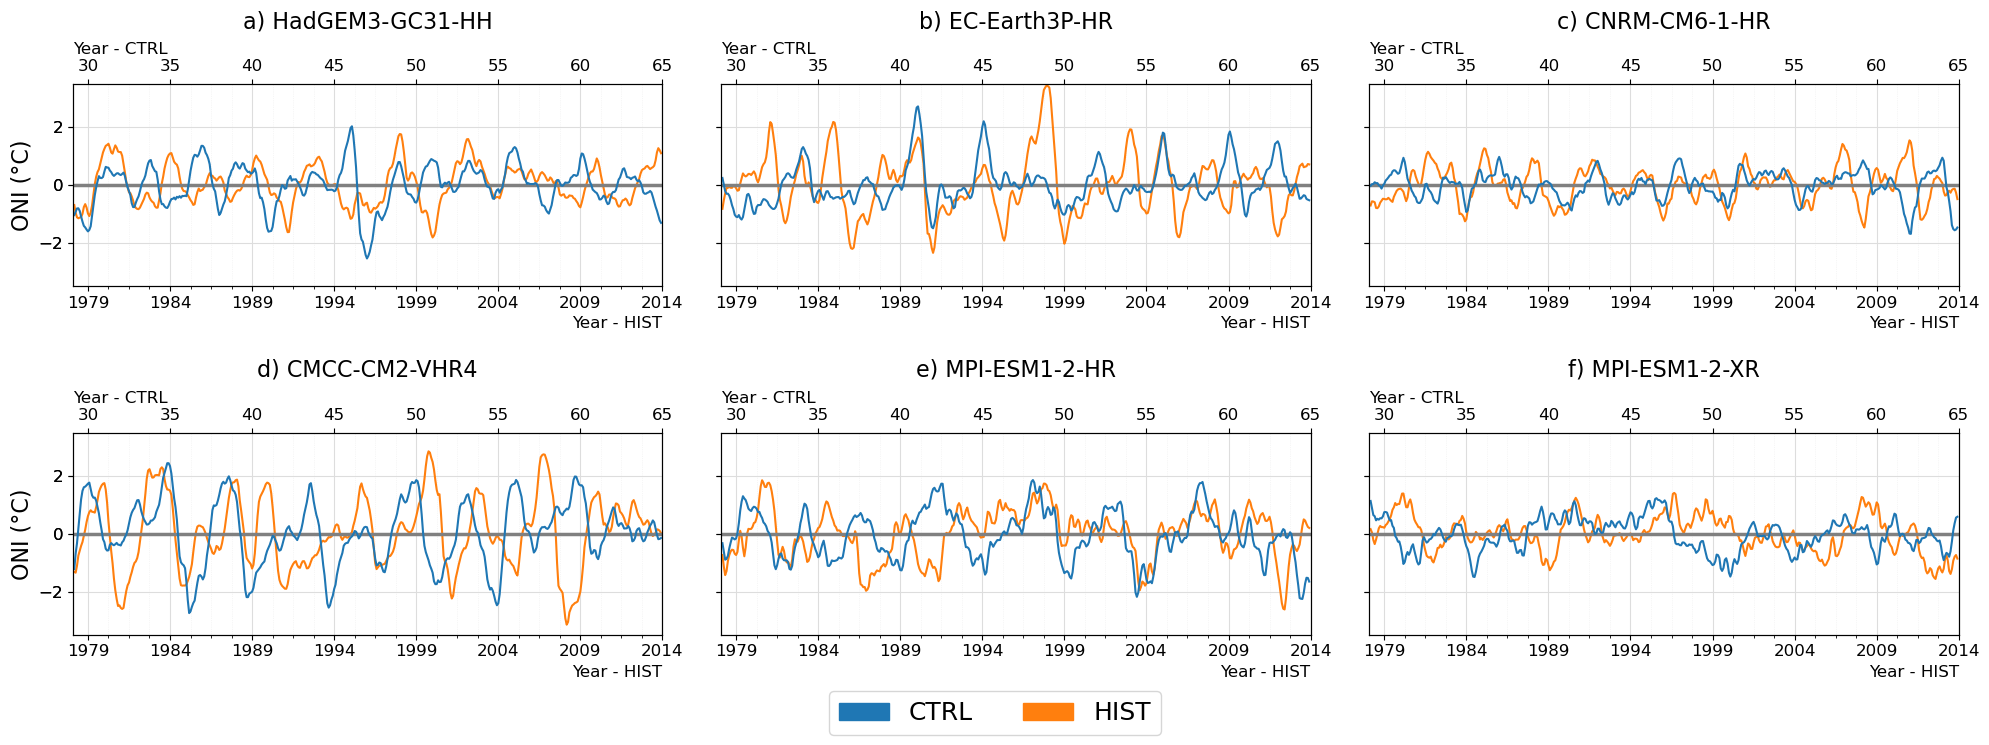

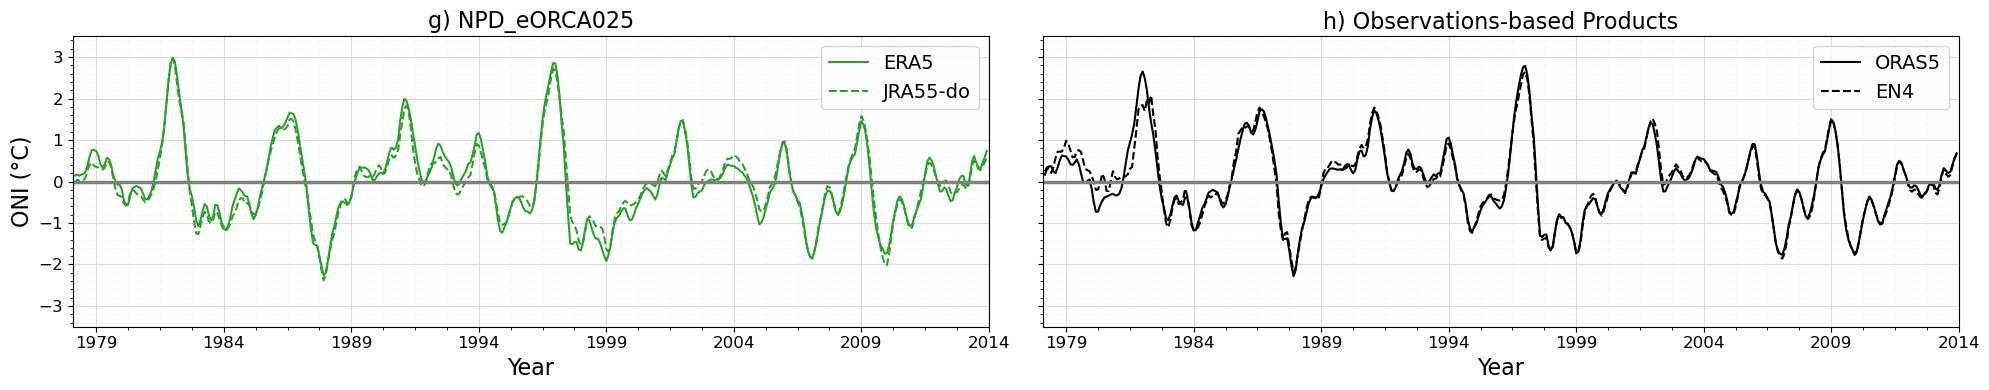

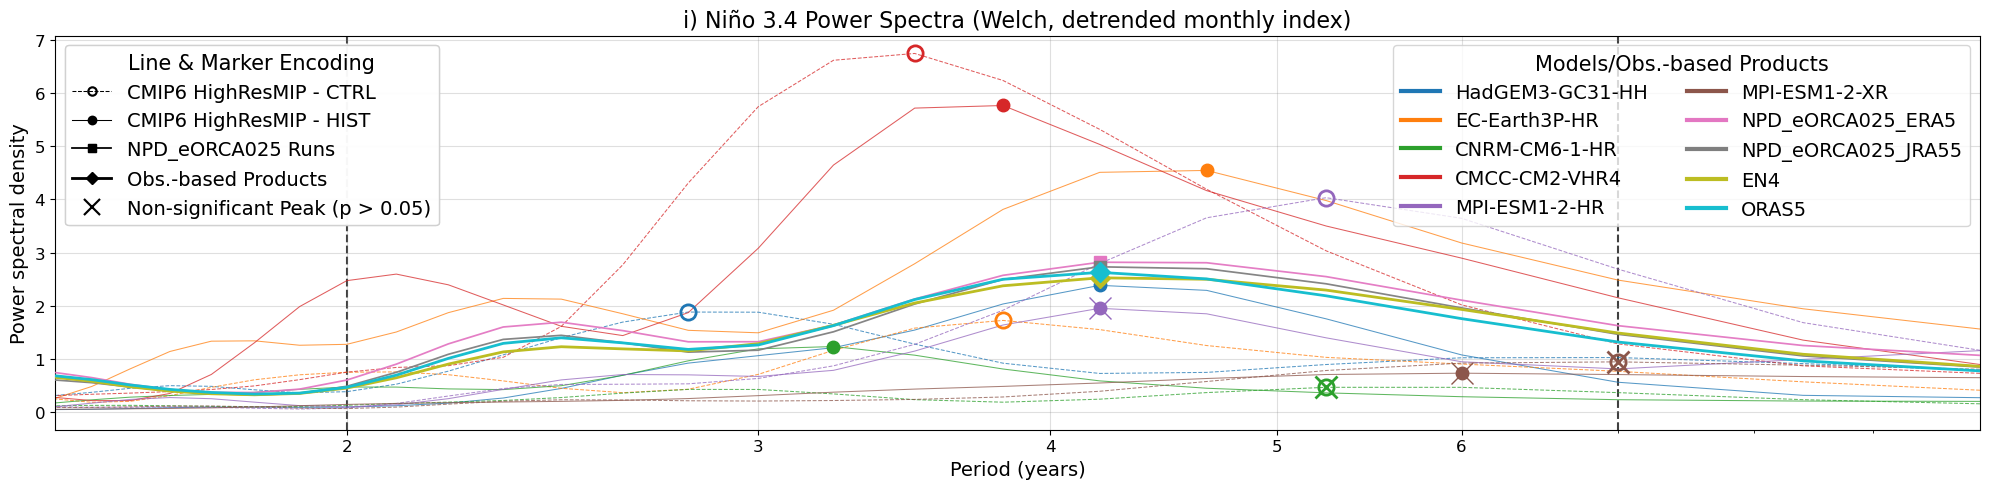

In [ ]:
# =============================================================================
# READING IN THE NIÑO 3.4 AND ONI TIME SERIES DATA
# =============================================================================
# Figure 2 shows the HIST_EVAL period
assert PERIOD_LABEL == PERIOD_LABELS['HIST'], 'Figure 2 needs PERIOD_LABEL = HIST_EVAL'

# Niño 3.4 index and ONI of all datasets for the period (written by enso_preprocessing.py)
n34_data = pd.read_csv(f'{DATA_DIR}N34_INDEX_{PERIOD_LABEL}.csv', 
                       index_col = 0, parse_dates = True)
oni_data = pd.read_csv(f'{DATA_DIR}ONI_{PERIOD_LABEL}.csv', 
                       index_col = 0, parse_dates = True)

# =============================================================================
# PLOTTING HIGHRESMIP_MODELS (BOTH 'CTRL' AND 'HIST') ONI TIMESERIES
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False, sharey=True)
axes = axes.ravel()

# Legend handles for CTRL vs HIST
legend_patches = [mpatches.Patch(color='C0', label='CTRL'),
                  mpatches.Patch(color='C1', label='HIST'),]

for i, (model, ax) in enumerate(zip(HIGHRESMIP_MODELS, axes)):
    # HIST on primary (bottom) axis
    oni_data[f'{model}_HIST'].plot(color='C1', ax=ax)
    format_axis(ax=ax, kind='oni', period=PERIOD_LABELS['HIST'])
    ax.set_xlabel('Year - HIST', fontsize=12, loc='right')

    # CTRL on twin (top) axis, with x tick labels in CTRL model years (1979 = model year 30)
    ax_ctrl = ax.twiny()
    oni_data[f'{model}_CTRL'].plot(color='C0', ax=ax_ctrl)
    format_axis(ax=ax_ctrl, kind='oni', period=PERIOD_LABELS['HIST'], twin=True, model_year_offset=30)
    ax_ctrl.set_xlabel('Year - CTRL', fontsize=12, loc='left')

    # Panel title
    panel_letter = chr(ord('a') + i)
    ax.set_title(f'{panel_letter}) {model}', fontsize=16, pad=10)

# Figure legend below the panels
fig.legend(handles=legend_patches, loc='lower center', fontsize=18, ncols=4,
           bbox_to_anchor=(0.5, -0.075))

fig.tight_layout(h_pad=2, w_pad=2)
fig.savefig(f'{FIG_DIR}figure_2_pt1.png', bbox_inches='tight', dpi=300)

# =============================================================================
# PLOTTING NPD_EXPS AND OBS ONI TIMESERIES
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(20, 4), sharex=True, sharey=True)
ax_left, ax_right = axes

# Left panel: NPD_eORCA025 (panel letters continue from the model panels above, where i = 5 after the loop)
oni_data['NPD_eORCA025_ERA5'].plot(color='C2', ax=ax_left, label='ERA5')
oni_data['NPD_eORCA025_JRA55'].plot(color='C2', ax=ax_left, label='JRA55-do', ls='--')
format_axis(ax_left, kind = 'oni', period = PERIOD_LABEL)
ax_left.set_title(f'{chr(ord('a') + i + 1)}) NPD_eORCA025', fontsize=16)
ax_left.legend(fontsize=14)

# Right panel: observations
oni_data['ORAS5'].plot(color='black', ax=ax_right, label='ORAS5')
oni_data['EN4'].plot(color='black', ax=ax_right, label='EN4', ls='--')
format_axis(ax_right, kind = 'oni', period = PERIOD_LABEL)
ax_right.set_title(f'{chr(ord('a') + i + 2)}) Observations-based Products', fontsize=16)
ax_right.legend(fontsize=14)

fig.tight_layout(h_pad=2, w_pad=2)
fig.savefig(f'{FIG_DIR}figure_2_pt2.png', bbox_inches='tight', dpi=300)

# =============================================================================
# PLOTTING POWER SPECTRAL DENSITY FOR EACH DATASET
# =============================================================================
fig, ax = plt.subplots(figsize=(20, 5))
peak_points = [] # Collect peak markers to draw last

# HighResMIP models (CTRL: dashed line and hollow marker, HIST: solid line and filled marker)
for base in HIGHRESMIP_MODELS:
    c = colours[base]
    for rt in ['CTRL', 'HIST']:
        colname = f'{base}_{rt}'
        line_kw = dict(linestyle='--' if rt == 'CTRL' else '-',
            linewidth=0.75, color=c, alpha=0.75, zorder=2,)
        if rt == 'CTRL':
            # Hollow circle
            peak_kw = dict(marker='o', mfc='none', mec=c, mew=2.0, ms=11, zorder=12,)
        else:
            # Filled circle
            peak_kw = dict(marker='o', mfc=c, mec=c, mew=1.0, ms=9, zorder=12,)
        plot_psd_series(series_name = colname, n34_data = n34_data, 
                        ax = ax, peak_points = peak_points, psd_kwargs = PSD_KW, 
                        line_kw = line_kw, peak_marker_kw = peak_kw, ns_lst = ns_lst)

# NPD runs
for name in NPD_EXPS:
    c = colours[name]
    line_kw = dict(linestyle='-', linewidth=1.25, color=c, alpha=0.95, zorder=3,)
    peak_kw = dict(marker='s', mfc=c, mec=c, mew=1.0, ms=9, zorder=13,)
    plot_psd_series(series_name = name, n34_data = n34_data, 
                    ax = ax, peak_points = peak_points, psd_kwargs = PSD_KW, 
                    line_kw = line_kw, peak_marker_kw = peak_kw, ns_lst = ns_lst)

# Observation-based products
for name in OBS:
    c = colours[name]
    line_kw = dict(linestyle='-', linewidth=2.0,color=c, alpha=1.0, zorder=4,)
    peak_kw = dict(marker='D', mfc=c, mec=c, mew=1.0,ms=10, zorder=14,)
    plot_psd_series(series_name = name, n34_data = n34_data, 
                    ax = ax, peak_points = peak_points, psd_kwargs = PSD_KW, 
                    line_kw = line_kw, peak_marker_kw = peak_kw, ns_lst = ns_lst)

# =============================================================================
# DRAWING PEAK MARKERS FOR EACH DATASET
# =============================================================================
for xv, yv, kw, significance in peak_points:
    ax.plot(xv, yv, linestyle='None', marker=kw['marker'], markersize=kw['ms'], 
            markerfacecolor=kw['mfc'], markeredgecolor=kw['mec'], markeredgewidth=kw['mew'], 
            zorder=kw['zorder'],)
    if significance == False: # Non-significant peak (p > 0.05): mark with a cross
        ax.plot(xv, yv, linestyle='None', marker='x', markersize=16, 
                    markerfacecolor=kw['mfc'], markeredgecolor=kw['mec'], markeredgewidth=kw['mew'], 
                    zorder=20,)

# =============================================================================
# AXES STYLING AND GUIDE LINES
# =============================================================================
format_axis(ax, kind = 'psd', panel_id = chr(ord('a') + i + 3))

# =============================================================================
# CONFIGURING LEGENDS FOR LINE COLOURS, MARKER ENCODING, ETC.
# =============================================================================
# Legend 1: colour, corresponding to dataset/model
handles1 = [Line2D([0], [0], color=colours[name], lw=3) 
            for name in HIGHRESMIP_MODELS + NPD_EXPS + OBS]
labels1 = list(HIGHRESMIP_MODELS + NPD_EXPS + OBS)
leg1 = ax.legend(handles1, labels1, title='Models/Obs.-based Products', 
                 loc='upper right', fontsize=14, ncol=2, title_fontsize=15,)
ax.add_artist(leg1)

# Legend 2: encoding (style/marker)
handles2 = [Line2D([0], [0], color='black', lw=0.75, ls='--', marker='o', mfc='none', mec='black', 
                   mew=1.5, label='CMIP6 HighResMIP - CTRL'),
            Line2D([0], [0], color='black', lw=0.75, ls='-', marker='o', mfc='black', mec='black', 
                   label='CMIP6 HighResMIP - HIST'),
            Line2D([0], [0], color='black', lw=1.25, ls='-', marker='s', mfc='black', mec='black', 
                   label='NPD_eORCA025 Runs'),
            Line2D([0], [0], color='black', lw=2.0, ls='-', marker='D', mfc='black', mec='black', 
                   label='Obs.-based Products'),
            Line2D([0], [0], color='black', lw=1.25, ls='None', marker='x', mfc='none', mec='black', 
                   mew=1.5, ms = 12, label='Non-significant Peak (p > 0.05)')]
leg2 = ax.legend(handles2, ['CMIP6 HighResMIP - CTRL', 'CMIP6 HighResMIP - HIST', 'NPD_eORCA025 Runs', 
                            'Obs.-based Products', 'Non-significant Peak (p > 0.05)'], 
                            title='Line & Marker Encoding', loc='upper left', 
                 fontsize=14, title_fontsize=15,)
ax.add_artist(leg2)

fig.tight_layout()
fig.savefig(f'{FIG_DIR}figure_2_pt3.png', bbox_inches='tight', dpi=300)

In [6]:
# =============================================================================
# MERGING ALL THREE FIGURES ABOVE INTO A SINGLE FIGURE
# =============================================================================
merge_pngs_vertical(
    [
        f"{FIG_DIR}figure_2_pt1.png",
        f"{FIG_DIR}figure_2_pt2.png",
        f"{FIG_DIR}figure_2_pt3.png",
    ],
    f"{FIG_DIR}figure_2.png",
)

### Figure 3: Group-mean ENSO Composites, Bias and 'Flavour' Proportions

In [ ]:
# Reading in the ENSO SSTA composite xarray.Dataset (written by appendices/appendix_A.ipynb). The file covers all periods;
# PERIOD_LABEL is only the key in ENSO_COMPOSITES. Along 'comp' it holds the six group means (CTRL, HIST, SCEN_F, SCEN_T,
# NPD, OBS; variable 'M') followed by the six group differences (HIST-OBS, CTRL-OBS, NPD-OBS, SCEN_F-HIST, SCEN_T-HIST,
# HIST-CTRL; variable 'D'), each with a boolean significance mask 'sig'
ENSO_COMPOSITES[PERIOD_LABEL] = xr.open_dataset(f'{DATA_DIR}ENSO_SSTA_COMP_DIFF_RESULTS_WITH_SIG.nc')

# ENSO flavour proportions (fraction of the events of each flavour) per dataset, from enso_preprocessing.py
ENSO_FLAV_PROP = pd.read_csv(f'{DATA_DIR}ENSO_FLAVOUR_PROPORTIONS_{PERIOD_LABEL}.csv', index_col=0)

# Group medians in %: one row per group of model experiments and observations
ENSO_FLAV_PROP_GRP_MEDIAN = pd.DataFrame([ENSO_FLAV_PROP.loc[HIGHRESMIP_EXPS_CTRL].median(axis=0).rename('CMIP6 HighResMIP (CTRL)'),
                                        ENSO_FLAV_PROP.loc[HIGHRESMIP_EXPS_HIST].median(axis=0).rename('CMIP6 HighResMIP (HIST)'),
                                        ENSO_FLAV_PROP.loc[NPD_EXPS].median(axis=0).rename('NPD_eORCA025 Runs'),
                                        ENSO_FLAV_PROP.loc[OBS].median(axis=0).rename('Obs.-based Products')]) * 100

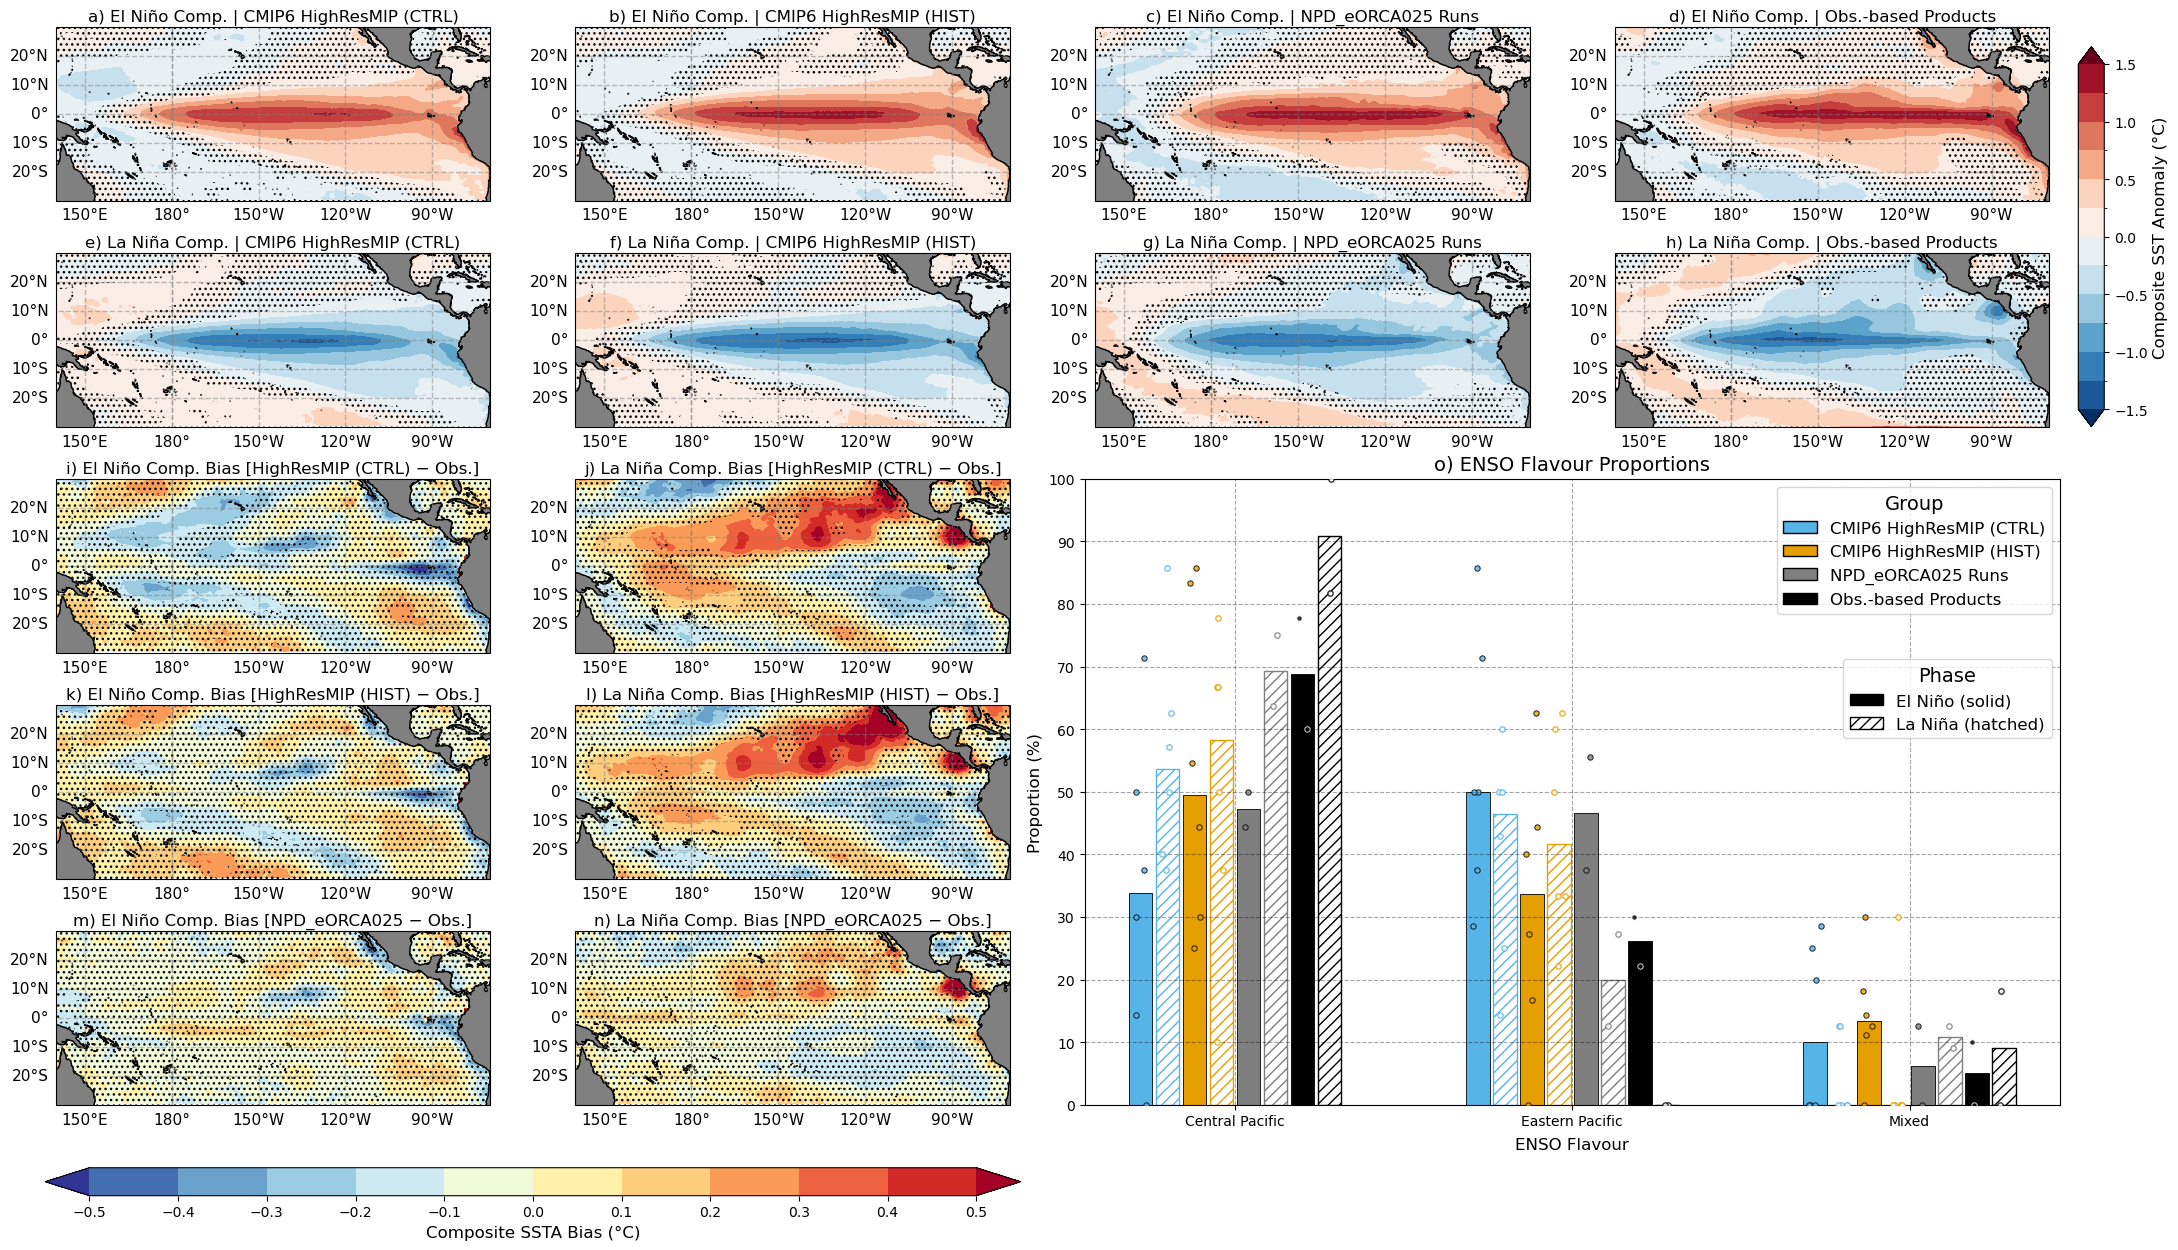

In [ ]:
# =============================================================================
# CONFIGURING THE FIGURE AND GRID SPECIFICATIONS
# =============================================================================
fig = plt.figure(figsize=(26, 14), constrained_layout=False)

# 5 rows and 4 columns:
#   rows 0-1: 2x4 ENSO composite maps
#   rows 2-4: 3x2 bias maps (columns 0-1) + flavour proportions bar chart (columns 2-3)
gs = fig.add_gridspec(nrows=5, ncols=4, height_ratios=[1.0, 1.0, 1.0, 1.0, 1.0], width_ratios=[1, 1, 1, 1], hspace=0.30, wspace=0.14)

# Top 2 rows: ENSO composites
projection = ccrs.PlateCarree(central_longitude=180)
ax_enso = np.empty((2, 4), dtype=object)
for r in range(2):
    for c in range(4):
        ax_enso[r, c] = fig.add_subplot(gs[r, c], projection=projection)

# Bias axes (left two columns, rows 2-4)
ax_bias = {}
ax_bias['EN_HIGHRESMIP_CTRL'] = fig.add_subplot(gs[2, 0], projection=projection)
ax_bias['LN_HIGHRESMIP_CTRL'] = fig.add_subplot(gs[2, 1], projection=projection)
ax_bias['EN_HIGHRESMIP_HIST'] = fig.add_subplot(gs[3, 0], projection=projection)
ax_bias['LN_HIGHRESMIP_HIST'] = fig.add_subplot(gs[3, 1], projection=projection)
ax_bias['EN_NPD_EXPS']   = fig.add_subplot(gs[4, 0], projection=projection)
ax_bias['LN_NPD_EXPS']   = fig.add_subplot(gs[4, 1], projection=projection)

# right-side axes spanning rows 2-4 of columns 2-3: flavour proportions bar chart
ax_flav_prop = fig.add_subplot(gs[2:5, 2:4])

# Contour levels and colourmaps
# composite maps
levels = np.arange(-1.5, 1.51, 0.25)
cmap_enso_composites = 'RdBu_r'

# Bias maps
levels_bias = np.arange(-0.50, 0.51, 0.10)
cmap_enso_bias = 'RdYlBu_r'

# =============================================================================
# UPPER PANELS: GROUP-MEAN COMPOSITES (2 × 4)
# =============================================================================
group_order = ['CTRL', 'HIST', 'NPD', 'OBS']

en_titles = ['a) El Niño Comp. | CMIP6 HighResMIP (CTRL)',
             'b) El Niño Comp. | CMIP6 HighResMIP (HIST)',
             'c) El Niño Comp. | NPD_eORCA025 Runs',
             'd) El Niño Comp. | Obs.-based Products',]
ln_titles = ['e) La Niña Comp. | CMIP6 HighResMIP (CTRL)',
             'f) La Niña Comp. | CMIP6 HighResMIP (HIST)',
             'g) La Niña Comp. | NPD_eORCA025 Runs',
             'h) La Niña Comp. | Obs.-based Products',]

mappable_enso = None

# Row 0: El Niño composites; row 1: La Niña composites (one column per group)
for row, (varname, titles) in enumerate([('EL-NINO', en_titles), ('LA-NINA', ln_titles)]):
    for col, (group_key, title) in enumerate(zip(group_order, titles)):
        ds_grp = ENSO_COMPOSITES[PERIOD_LABEL].sel(comp = group_key).squeeze()
        ds_phase = ds_grp.sel(phase = varname).squeeze()
        da = ds_phase['M']
        da_sig = ds_phase['sig']

        mappable_enso = da.plot.contourf(ax=ax_enso[row, col], transform=ccrs.PlateCarree(), x='lon', y='lat', 
                                         cmap=cmap_enso_composites, add_colorbar=False, levels=levels, extend='both')
        c_hatch = ax_enso[row, col].contourf(da_sig.lon, da_sig.lat, da_sig.astype(float), levels=[-0.5, 0.5], hatches=['...'], 
                                             colors='none', transform=ccrs.PlateCarree())
        # Customising the hatch/stipple colour
        c_hatch._hatch_color = color_shade

        format_axis(ax = ax_enso[row, col], kind = 'map', land_ft = land_50m, coast_ft = coast_50m)
        ax_enso[row, col].set_title(title, fontsize=12, pad=4)


# =============================================================================
# LOWER LEFT: BIAS MAPS (3 × 2)
# =============================================================================
mappable_bias = None

# Bias of each group relative to the observation-based products: (comp, phase, axes key, title) in plotting order
bias_specs = [('CTRL-OBS', 'EL-NINO', 'EN_HIGHRESMIP_CTRL', 'i) El Niño Comp. Bias [HighResMIP (CTRL) − Obs.]'),
              ('CTRL-OBS', 'LA-NINA', 'LN_HIGHRESMIP_CTRL', 'j) La Niña Comp. Bias [HighResMIP (CTRL) − Obs.]'),
              ('HIST-OBS', 'EL-NINO', 'EN_HIGHRESMIP_HIST', 'k) El Niño Comp. Bias [HighResMIP (HIST) − Obs.]'),
              ('HIST-OBS', 'LA-NINA', 'LN_HIGHRESMIP_HIST', 'l) La Niña Comp. Bias [HighResMIP (HIST) − Obs.]'),
              ('NPD-OBS', 'EL-NINO', 'EN_NPD_EXPS', 'm) El Niño Comp. Bias [NPD_eORCA025 − Obs.]'),
              ('NPD-OBS', 'LA-NINA', 'LN_NPD_EXPS', 'n) La Niña Comp. Bias [NPD_eORCA025 − Obs.]'),]

for comp, varname, ax_key, title in bias_specs:
    ds_bias = ENSO_COMPOSITES[PERIOD_LABEL].sel(comp = comp, phase = varname).squeeze()
    da_bias = ds_bias['D']
    da_bias_sig = ds_bias['sig']
    mappable_bias = da_bias.plot.contourf(ax=ax_bias[ax_key], transform=ccrs.PlateCarree(), x='lon', y='lat',
                                          cmap=cmap_enso_bias, add_colorbar=False, levels=levels_bias, extend='both')
    c_hatch = ax_bias[ax_key].contourf(da_bias_sig.lon, da_bias_sig.lat, da_bias_sig.astype(float), levels=[-0.5, 0.5], hatches=['...'],
                                       colors='none', transform=ccrs.PlateCarree())
    # Customising the hatch/stipple colour
    c_hatch._hatch_color = color_shade

    format_axis(ax = ax_bias[ax_key], kind = 'map', land_ft = land_50m, coast_ft = coast_50m)
    ax_bias[ax_key].set_title(title, fontsize=12, pad=4)

# =============================================================================
# ENSO FLAVOUR PROPORTION BARCHART (BOTTOM RIGHT)
# =============================================================================
# order of the bars within each flavour: the El Niño (EN) and La Niña (LN) bar of CTRL, HIST, NPD and OBS
order = [('EN', 'CMIP6 HighResMIP (CTRL)'), ('LN', 'CMIP6 HighResMIP (CTRL)'),
         ('EN', 'CMIP6 HighResMIP (HIST)'), ('LN', 'CMIP6 HighResMIP (HIST)'),
         ('EN', 'NPD_eORCA025 Runs'), ('LN', 'NPD_eORCA025 Runs'),
         ('EN', 'Obs.-based Products'),('LN', 'Obs.-based Products'),]

# Bar chart config
colours_grp = {'CMIP6 HighResMIP (CTRL)': '#56B4E9', # Blue
               'CMIP6 HighResMIP (HIST)': '#E69F00', # Orange
               'NPD_eORCA025 Runs': '#7F7F7F', # Grey
               'Obs.-based Products': '#000000',} # Black

# Individual datasets of each group, selected by their names in the index of ENSO_FLAV_PROP (OBS: all the others)
raw_subsets = {'CMIP6 HighResMIP (CTRL)': ENSO_FLAV_PROP[ENSO_FLAV_PROP.index.str.contains('CTRL')],
               'CMIP6 HighResMIP (HIST)': ENSO_FLAV_PROP[ENSO_FLAV_PROP.index.str.contains('HIST')],
               'NPD_eORCA025 Runs': ENSO_FLAV_PROP[ENSO_FLAV_PROP.index.str.contains('NPD')],
               'Obs.-based Products': ENSO_FLAV_PROP[~ENSO_FLAV_PROP.index.str.contains('CTRL|HIST|NPD')]}

x, bar_width, gap = np.arange(len(flavours)), 0.07, 0.01

for i, (phase, grp) in enumerate(order):
    # The 8 bars (EN and LN of 4 groups) are centred on each flavour tick
    offsets = (-3.5 * bar_width - 3.5 * gap) + i * (bar_width + gap)
    xpos = x + offsets

    # CSV columns of this phase, and the group median of each
    cols_to_plot = [col_map[phase][f] for f in flavours]
    vals = [ENSO_FLAV_PROP_GRP_MEDIAN.loc[grp, col] for col in cols_to_plot]
    if phase == 'EN':
        # El Niño: filled bars
        ax_flav_prop.bar(xpos, vals, width=bar_width, color=colours_grp[grp], edgecolor='black', linewidth=0.6)
    else:
        # La Niña: hatched bars
        ax_flav_prop.bar(xpos, vals, width=bar_width, color='none', edgecolor=colours_grp[grp], hatch=hatch_style, linewidth=1.0)

    raw_subset = raw_subsets[grp]

    # Scatter the individual points
    for j, col in enumerate(cols_to_plot):
        # Multiply by 100 to convert the fractions to percentages
        y_vals = raw_subset[col].dropna().values * 100
        x_vals = np.full(len(y_vals), xpos[j])
        
        # Unseeded jitter to prevent overlapping data points (differs from run to run)
        jitter_vals = np.random.uniform(-bar_width/4, bar_width/4, size=len(y_vals))
        
        if 'EN' in col:
            ax_flav_prop.scatter(x_vals + jitter_vals, y_vals, color=colours_grp[grp], edgecolor='black' if 'Obs.' not in grp else 'white', linewidth=0.75,s=15, alpha=0.8, zorder=3)
        elif 'LN' in col:
            ax_flav_prop.scatter(x_vals + jitter_vals, y_vals, color='white', edgecolor=colours_grp[grp], linewidth=1.0,s=15, alpha=0.8, zorder=3)

# Axes of the bar chart
ax_flav_prop.set_xticks(x)
ax_flav_prop.set_xticklabels(['Central Pacific', 'Eastern Pacific', 'Mixed'], fontsize=10)
ax_flav_prop.set_yticks(np.arange(0, 101, 10))
ax_flav_prop.set_xlabel('ENSO Flavour', fontsize=12, labelpad=6)
ax_flav_prop.set_ylabel('Proportion (%)', fontsize=12)
ax_flav_prop.set_ylim(0, 100)
ax_flav_prop.grid(visible = True, ls = '--', alpha = 0.35, color = 'k')
ax_flav_prop.set_title('o) ENSO Flavour Proportions', fontsize=14)
ax_flav_prop.tick_params(axis='both', labelsize=10)

# Legend 1: groups (colours_grp) - upper right
group_handles = [mpatches.Patch(facecolor=colours_grp[g], edgecolor='black', label=g)for g in colours_grp]
legend_groups = ax_flav_prop.legend(handles=group_handles, title='Group',loc='upper right', fontsize=12, title_fontsize=14)

# Legend 2: phase (bar style in black) - upper right, below legend 1
phase_handles = [mpatches.Patch(facecolor='black', edgecolor='black', label='El Niño (solid)'), 
                 mpatches.Patch(facecolor='none', edgecolor='black', hatch=hatch_style, label='La Niña (hatched)')]
ax_flav_prop.legend(handles=phase_handles, title='Phase', loc='upper right', bbox_to_anchor=(1.0, 0.725), fontsize=12, title_fontsize=14)

# Keeping both legends (a second legend() call replaces the first, which is therefore re-added as an artist)
ax_flav_prop.add_artist(legend_groups)

# =============================================================================
# SHARED COLOURBARS
# =============================================================================

# Shared vertical colourbar for ENSO composites
enso_axes_all = list(ax_enso[0, :]) + list(ax_enso[1, :])
add_colorbar(fig, axes = enso_axes_all, mappable = mappable_enso,
             label = 'Composite SST Anomaly (°C)', ticks=np.arange(-1.5, 1.51, 0.5), side = 'right', 
             height_scale=0.95, labelsize = 12, ticksize = 10)

# Shared horizontal colourbar for bias maps
bias_axes = [ax_bias['EN_HIGHRESMIP_CTRL'], ax_bias['LN_HIGHRESMIP_CTRL'], ax_bias['EN_HIGHRESMIP_HIST'], ax_bias['LN_HIGHRESMIP_HIST'], ax_bias['EN_NPD_EXPS'], ax_bias['LN_NPD_EXPS']]
add_colorbar(fig, axes = bias_axes, mappable = mappable_bias,
             label = 'Composite SSTA Bias (°C)', ticks=levels_bias, side = 'bottom', 
             height=0.020, pad = 0.065, labelsize = 12, ticksize = 10)

fig.savefig(f'{FIG_DIR}figure_3.png', bbox_inches='tight', dpi=300)

### Figure 4: KDE of peak ENSO SST anomaly positions

In [12]:
# =============================================================================
# READING IN THE GAUSSIAN KDE DATA FOR |SST|_MAX ANOMALY POSITIONS
# =============================================================================
# Gaussian KDE of the positions of the maximum |SSTA| within 5S-5N and 140-270E (all El Niño / La Niña months),
# per dataset and ENSO phase (written by enso_preprocessing.py)
gaussian_kde_combined = xr.open_dataset(f'{DATA_DIR}GAUSS_KDE_5S5N_{PERIOD_LABEL}.nc')

# =============================================================================
# GROUP-MEAN KDEs (AVERAGED ACROSS THE DATASETS IN EACH GROUP)
# =============================================================================
groups = {'CMIP6 HighResMIP (CTRL)': HIGHRESMIP_EXPS_CTRL,
          'CMIP6 HighResMIP (HIST)': HIGHRESMIP_EXPS_HIST,
          'NPD_eORCA025 Runs': NPD_EXPS,
          'Obs.-based Products': OBS}

gaussian_by_group = xr.concat([gaussian_kde_combined.sel(dataset=d_list).mean(dim='dataset')
                               for d_list in groups.values()], dim=pd.Index(list(groups.keys()), name='group'))

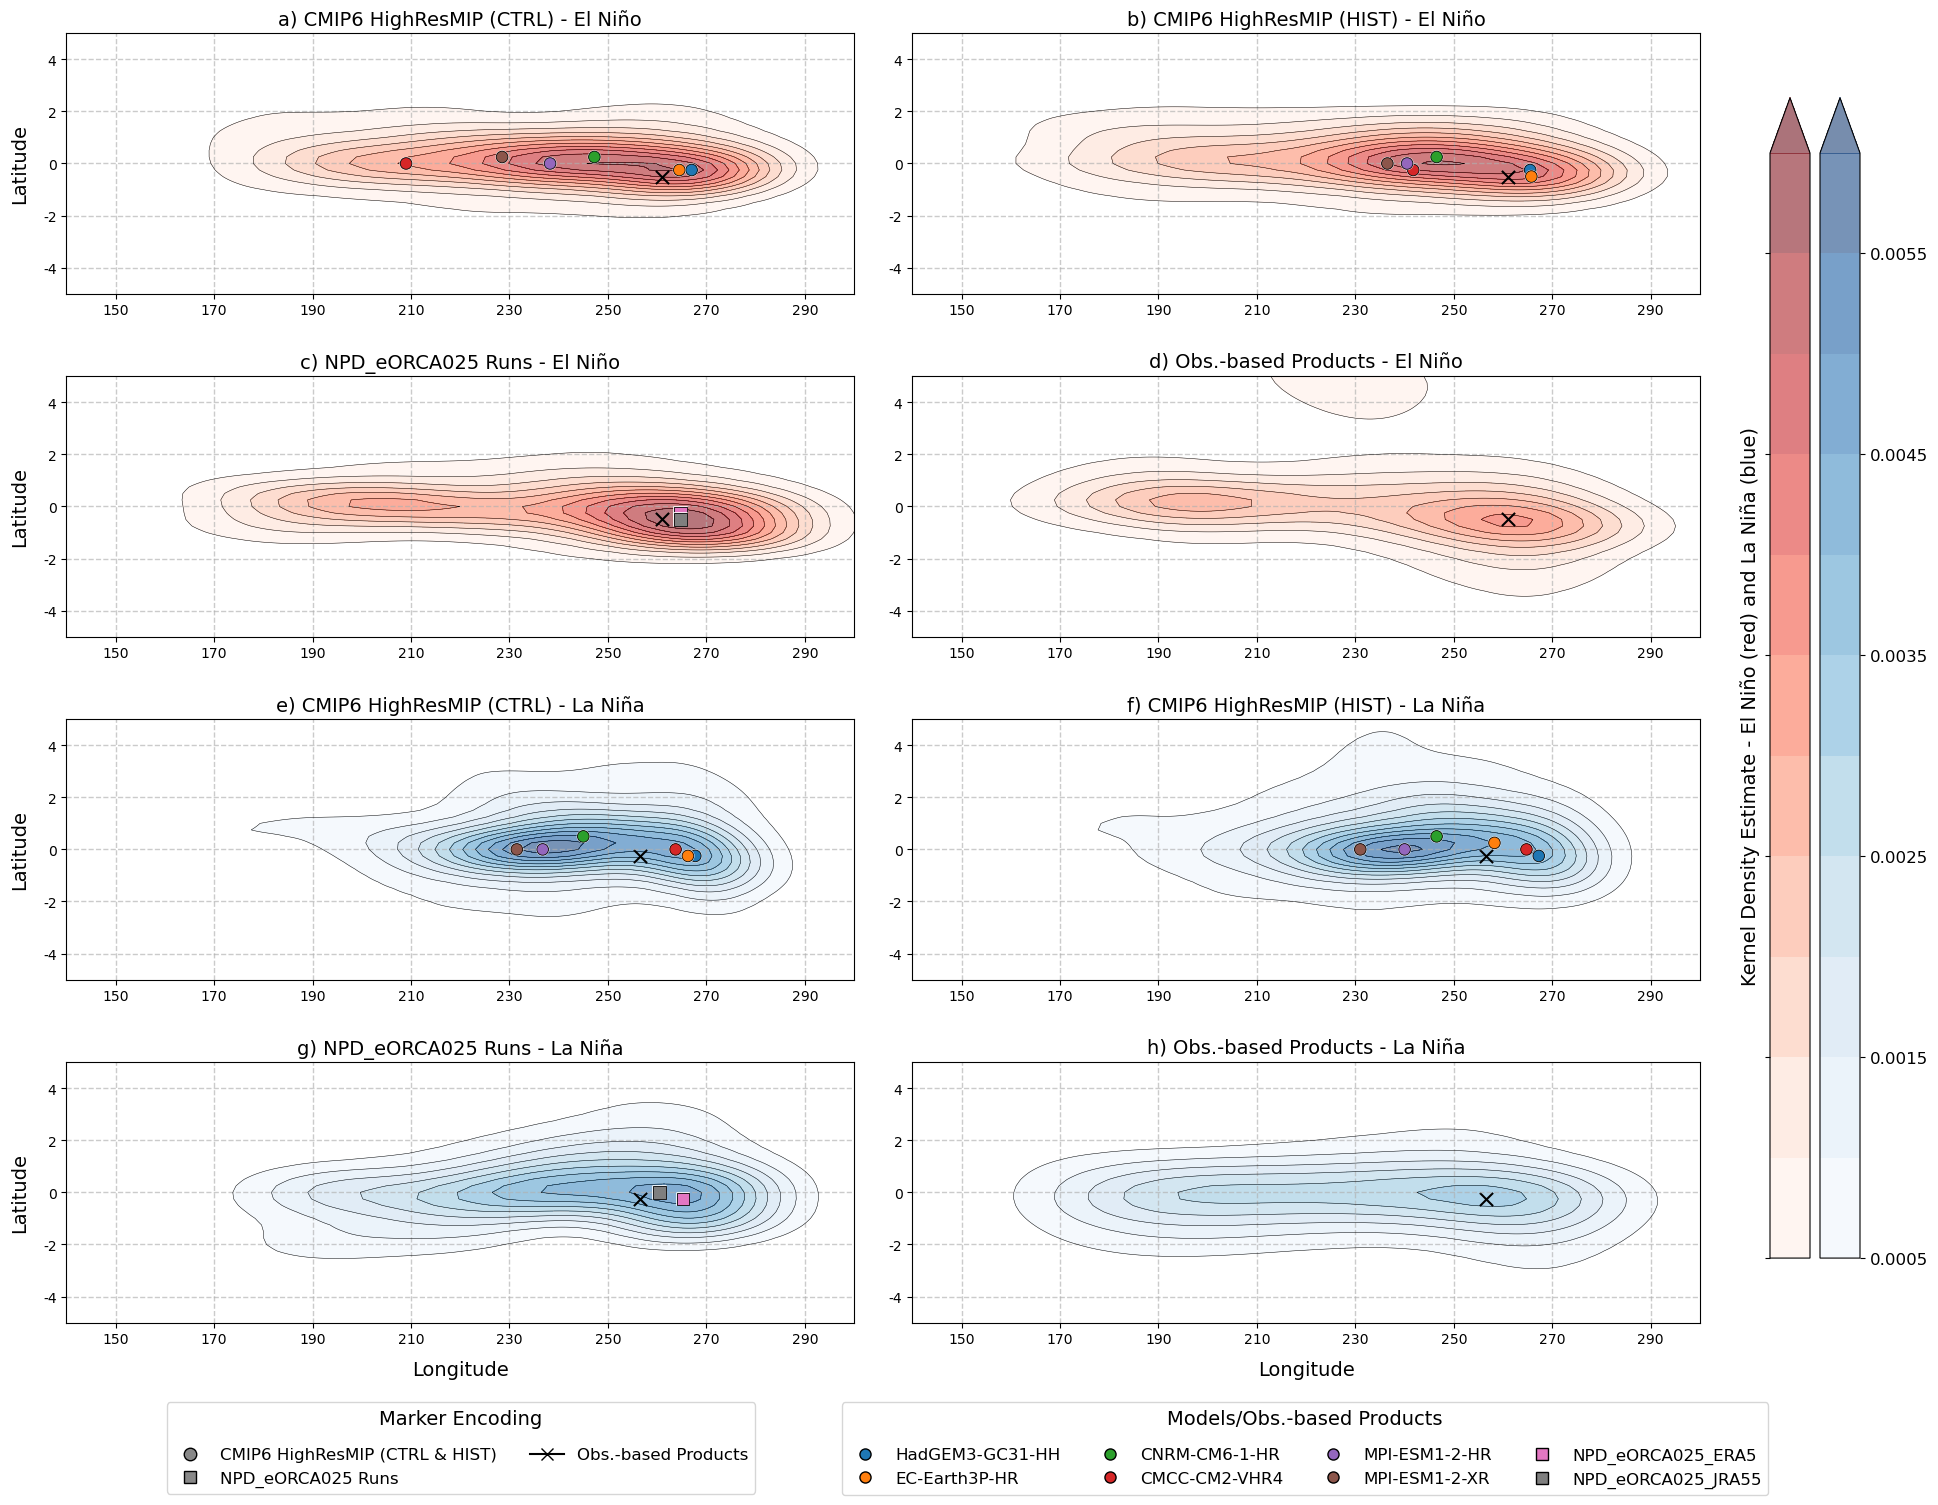

In [ ]:
# =============================================================================
# FIGURE 4: GROUP-MEAN KDEs (CTRL | HIST | NPD | OBS) - EL NIÑO (TOP TWO ROWS) vs LA NIÑA (BOTTOM TWO ROWS)
# =============================================================================
labels    = list(string.ascii_lowercase) # Panel labels (a, b, c, ...)
label_idx = 0 # Running panel-label counter
cbar_info = [] # Colourbar info (mappable, label, phase), used to draw the colourbars after tight_layout
# Lat/lon mesh the KDEs are drawn on
lons, lats = np.meshgrid(gaussian_by_group['lon'], gaussian_by_group['lat'])
fig, axes = plt.subplots(4, 2, figsize=(20, 14), sharex=True, sharey=True)
axes_flat = list(axes.flatten()) # Panels in reading order

for enso_phase in ['EL-NINO', 'LA-NINA']:
    # Each phase gets its own colourmap and 2x2 block of panels (El Niño: top two rows; La Niña: bottom two rows)
    if enso_phase == 'EL-NINO':
        color_map = 'Reds'
        axes_lst = [axes[0,0], axes[0,1], axes[1,0], axes[1,1]]
        title_label = 'El Niño'
    else:
        color_map = 'Blues'
        axes_lst = [axes[2,0], axes[2,1], axes[3,0], axes[3,1]]
        title_label = 'La Niña'

    # KDE peak of the Obs.-based group mean, marked with an 'x' on every panel of this phase
    lon_o, lat_o = peak_lonlat(gaussian_by_group.sel(group='Obs.-based Products', enso_phase=enso_phase)['GAUSS_KDE'])

    for i, (group, ax) in enumerate(zip(['CMIP6 HighResMIP (CTRL)', 'CMIP6 HighResMIP (HIST)', 'NPD_eORCA025 Runs', 'Obs.-based Products'], axes_lst)):
        kde = gaussian_by_group.sel(group=group, enso_phase=enso_phase)['GAUSS_KDE']
        c = ax.contourf(lons, lats, kde, cmap=color_map, levels=levels_kde, extend='max', alpha=0.55) # Filled KDE
        ax.contour(lons, lats, kde, colors='k', levels=levels_kde, linewidths=0.35) # KDE contour lines
        ax.set_title(f'{labels[label_idx]}) {group} - {title_label}', fontsize=14)
        format_axis(ax, kind='kde')
        ax.scatter(lon_o, lat_o, marker='x', color='k', s=90, label='Obs.-based Products')
        # Axis labels only on the bottom row (x) and the figure's leftmost column (y)
        ax.set_xlabel('Longitude' if axes_flat.index(ax) >= 6 else '', fontsize=14, labelpad=10)
        ax.set_ylabel('Latitude' if (axes_flat.index(ax) % 2 == 0) else '', fontsize=14, labelpad=10)
        # Tick labels shown on every panel despite the shared axes
        ax.tick_params(left=True, labelleft=True)
        ax.tick_params(bottom=True, labelbottom=True)
        label_idx += 1

    # KDE peak of each NPD run (squares) on the NPD panel
    for mod in NPD_EXPS:
        lon_r, lat_r = peak_lonlat(gaussian_kde_combined.sel(dataset=mod, enso_phase=enso_phase)['GAUSS_KDE'])
        axes_lst[2].scatter(lon_r, lat_r, marker='s', s=80, facecolor=colours[mod], edgecolor='k',
                            linewidth=0.6, zorder=6, label=mod,
                            path_effects=[pe.withStroke(linewidth=1.2, foreground='white')])

    # KDE peak of each HighResMIP model (circles) on the CTRL and HIST panels
    for mod in HIGHRESMIP_MODELS:
        # CTRL peak
        lon_c, lat_c = peak_lonlat(gaussian_kde_combined.sel(dataset=mod + '_CTRL', enso_phase=enso_phase)['GAUSS_KDE'])
        # La Niña CTRL peaks of HadGEM3-GC31-HH and EC-Earth3P-HR lie close together in the Niño 3.4 region: shift them by +/-0.75° in
        # longitude so that their markers do not overlap
        if (enso_phase == 'LA-NINA'):
            if (mod == 'HadGEM3-GC31-HH'):
                lon_c += 0.75
            elif (mod == 'EC-Earth3P-HR'):
                lon_c -= 0.75
        axes_lst[0].scatter(lon_c, lat_c, marker='o', s=70, facecolor=colours[mod], edgecolor='k', label=mod,
                            linewidth=0.6, zorder=6, path_effects=[pe.withStroke(linewidth=1.2, foreground='white')])

        # HIST peak
        lon_h, lat_h = peak_lonlat(gaussian_kde_combined.sel(dataset=mod + '_HIST', enso_phase=enso_phase)['GAUSS_KDE'])
        axes_lst[1].scatter(lon_h, lat_h, marker='o', s=70, facecolor=colours[mod], edgecolor='k',
                            linewidth=0.6, zorder=6, path_effects=[pe.withStroke(linewidth=1.2, foreground='white')])

    # Vertical colourbars spanning all panels, placed side by side
    cbar_info.append((c, title_label, enso_phase)) # Colourbars are drawn after tight_layout


# Figure legends below the panels (proxy artists)
# Legend 1: Models/NPD runs (colours)
color_handles = ([Line2D([0], [0], marker='o', color='w', label=name, markerfacecolor=colours[name],
                         markeredgecolor='k', markersize=8) for name in HIGHRESMIP_MODELS] +
                 [Line2D([0], [0], marker='s', color='w', label=run, markerfacecolor=colours[run],
                         markeredgecolor='k', markersize=8) for run in NPD_EXPS])
leg1 = fig.legend(handles=color_handles, loc='upper center', bbox_to_anchor=(0.655, 0), ncols=4,
                  frameon=True, fontsize=12, title='Models/Obs.-based Products')
leg1.get_title().set_fontsize(14)
leg1._legend_box.sep = 14

# Legend 2: Marker encoding (which marker shape stands for which kind of dataset)
style_handles = [Line2D([0], [0], marker='o', color='w', label='CMIP6 HighResMIP (CTRL & HIST)',
                        markerfacecolor='#888', markeredgecolor='k', markersize=9),
                 Line2D([0], [0], marker='s', color='w', label='NPD_eORCA025 Runs',
                        markerfacecolor='#888', markeredgecolor='k', markersize=9),
                 Line2D([0], [0], marker='x', color='k', label='Obs.-based Products', markersize=9)]
leg2 = fig.legend(handles=style_handles, loc='upper center', bbox_to_anchor=(0.233, 0), ncols=2,
                  frameon=True, fontsize=12, title='Marker Encoding')
leg2.get_title().set_fontsize(14)
leg2._legend_box.sep = 14

fig.tight_layout(h_pad=2.5, w_pad=2.5, rect=[0, 0, 0.86, 1]) # Leave the right 14% of the figure for the colourbars
fig.canvas.draw() # Make sure the axes positions are final

# =============================================================================
# DRAWING THE COLOURBARS FOR KDEs (EL NIÑO: REDS, LA NIÑA: BLUES)
# =============================================================================
width, gap, pad = 0.020, 0.005, 0.035
height_scale = 0.90
all_box = Bbox.union([ax.get_position(fig).frozen() for ax in axes.flat])

# Draw the colourbars after tight_layout to avoid them being squashed by the layout engine
for c, title_label, enso_phase in cbar_info:
    x0 = all_box.x1 + pad + (0 if enso_phase == 'EL-NINO' else width + gap)
    y0 = all_box.y0 + all_box.height * (1 - height_scale) / 2
    cax = fig.add_axes([x0, y0, width, all_box.height * height_scale])
    cb = fig.colorbar(c, cax=cax, orientation='vertical', ticks=list(np.arange(0.0005, 0.0065, 0.001)))
    cb.ax.tick_params(labelsize=12)
    if enso_phase == 'EL-NINO':
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        cb.ax.tick_params(labelleft=False)
        cb.set_label('Kernel Density Estimate - El Niño (red) and La Niña (blue)', fontsize=14)

# Saving the figure
fig.savefig(f'{FIG_DIR}figure_4.png', bbox_inches='tight', dpi=300)

### Figure 5: Event-centred group-mean composites of vertical temperature anomalies

In [ ]:
# =============================================================================
# READING IN THE NIÑO 3.4 HOVMÖLLER EVENT COMPOSITES
# =============================================================================
# Event-centred composites (variables M, D and sig; comps as in the SSTA file) written by appendices/appendix_A.ipynb,
# on the event time (-14 to +8 months) and depth (0-300 m)
ENSO_N34_HOV_EVENT_COMPOSITE = xr.open_dataset(f'{DATA_DIR}ENSO_N34_HOV_COMP_DIFF_RESULTS_WITH_SIG.nc')

# =============================================================================
# READING IN THE NIÑO 3.4 DEPTH VS. TIME (HOVMÖLLER) DATA
# =============================================================================
# Niño 3.4 temperature anomalies of the top 300 m, dims (dataset, time, depth), written by enso_preprocessing.py
N34_HOV_ZVT = xr.open_dataset(f'{DATA_DIR}N34_HOV_ZVT_TOP300M_{PERIOD_LABEL}.nc')

# =============================================================================
# BLOCK BOOTSTRAP OF THE GROUP-MEAN NIÑO 3.4 MEAN AND VARIANCE PROFILES
# =============================================================================
# Two-level block bootstrap of each group (CTRL, HIST, NPD, OBS): the datasets are resampled with replacement, then each
# resampled dataset is cut into BLOCK_SIZE-month blocks along 'time', which are resampled with replacement. The group
# mean of the absolute-mean and variance profiles is computed for each of the N_SIM draws; their 2.5-97.5% range gives the
# 95% CI of the group-mean profiles (BLOCK_SIZE and N_SIM are set in the constants cell)
group_n34_stats = [] # Empty list to store the group datasets containing the actual and bootstrapped statistics for each group
for i, (d_list, label) in tqdm(enumerate(zip([HIGHRESMIP_EXPS_CTRL, HIGHRESMIP_EXPS_HIST, NPD_EXPS, OBS], ['HighResMIP-CTRL', 'HighResMIP-HIST', 'NPD', 'OBS']))):
    ds = N34_HOV_ZVT.sel(dataset = d_list) # Selecting the datasets corresponding to the current group
    # Random number generator seeded with the group index (0-3) for reproducibility (not the seeds of appendix_A.ipynb)
    rng = np.random.default_rng(seed=i)

    # Calculating the mean and variance across the time axis for each dataset, followed by a group-mean operation
    ACTUAL_STATS = xr.merge([abs(ds['anomaly']).mean(dim = ['time']).rename('mean'),
                            ds['anomaly'].var(dim = ['time']).rename('var')]).mean(dim = 'dataset')

    # Empty list to store the bootstrapped group-mean statistics for each iteration
    boot_stats = []
    for b in tqdm(range(N_SIM), leave = False, desc = f'Bootstrapping - {label} : '):
        full_ds = [] # Empty list to store the resampled datasets' profiles for each iteration
        # Resampling the datasets with replacement along the 'dataset' dimension
        resampled_ds = ds.isel(dataset = rng.integers(0, ds.dataset.shape[0], size=ds.dataset.shape[0]))
        for _ in range(resampled_ds['dataset'].shape[0]): # Iterating over each resampled dataset
            da = resampled_ds.isel(dataset = [_]).anomaly 
            # Reshaping the data array into blocks of size BLOCK_SIZE along the 'time' dimension
            da_reshaped = da.values.reshape(da.shape[0], da.shape[1] // BLOCK_SIZE, BLOCK_SIZE, da.shape[-1])
            # Resampling the blocks with replacement along the second dimension (blocks)
            da_resampled = da_reshaped[:, rng.integers(0, da_reshaped.shape[1], size=da_reshaped.shape[1]), :, :]
            # Reshaping the resampled blocks back into the original shape
            da_resampled = da_resampled.reshape(da_reshaped.shape[0], 
                                                da_reshaped.shape[1] * da_reshaped.shape[2], 
                                                da_reshaped.shape[-1],)
            da[:] = da_resampled # Assigning the resampled data back to the original data array

            # Renaming the resampled data array and adding a new dimension for bootstrapping
            da = da.rename('anomaly_resampled').expand_dims({'boot':[b]}) 
            full_ds += [da.to_dataset()] # Adding the resampled data array (as a dataset) to the list of datasets for this iteration
        full_ds = xr.concat(full_ds, dim = 'dataset') # Concatenating the resampled datasets along the 'dataset' dimension
        # Calculating the mean and variance across the time axis for each resampled dataset, followed by a group-mean operation, and adding the results to the list of bootstrapped statistics
        boot_stats += [xr.merge([abs(full_ds['anomaly_resampled']).mean(dim = ['time']).rename('mean_boot'),
                                full_ds['anomaly_resampled'].var(dim = ['time']).rename('var_boot')]).mean(dim = 'dataset')]
    # Concatenating the bootstrapped statistics along the 'boot' dimension to create a single dataset containing all bootstrapped group-mean statistics for this group
    boot_stats = xr.concat(boot_stats, dim = 'boot')
    # Merging the actual group-mean statistics and the bootstrapped statistics into a single dataset, and adding a new dimension for the group label
    group_n34_stats += [xr.merge([ACTUAL_STATS, boot_stats]).expand_dims({'group':[label]})]

group_n34_stats = xr.concat(group_n34_stats, dim = 'group') # Concatenating the group datasets along the 'group' dimension

# Calculating the pairwise differences between each group's bootstrapped mean and variance and the OBS group's bootstrapped mean and variance
pairwise_diff = xr.merge([group_n34_stats['mean_boot'] - group_n34_stats['mean_boot'].sel(group = 'OBS'), 
                          group_n34_stats['var_boot'] - group_n34_stats['var_boot'].sel(group = 'OBS')])

# Adding the two-sided bootstrap p-values (p_val_calculation) of the differences to group_n34_stats as new variables
group_n34_stats['pval_mean'] = p_val_calculation(pairwise_diff['mean_boot']).rename('pval_mean')
group_n34_stats['pval_var'] = p_val_calculation(pairwise_diff['var_boot']).rename('pval_var')

0it [00:00, ?it/s]

Bootstrapping - HighResMIP-CTRL :   0%|          | 0/2000 [00:00<?, ?it/s]

Bootstrapping - HighResMIP-HIST :   0%|          | 0/2000 [00:00<?, ?it/s]

Bootstrapping - NPD :   0%|          | 0/2000 [00:00<?, ?it/s]

Bootstrapping - OBS :   0%|          | 0/2000 [00:00<?, ?it/s]

/dssgfs01/working/sg13n23/ENSO-HighResMIP-TempAnoms/utils.py:828: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axhspan(100, 150, color='gray', edgecolor='k', alpha=0.25, linewidth=2)
/tmp/ipykernel_3898325/2261113106.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0.04, 0.09, 0.98, 0.98))


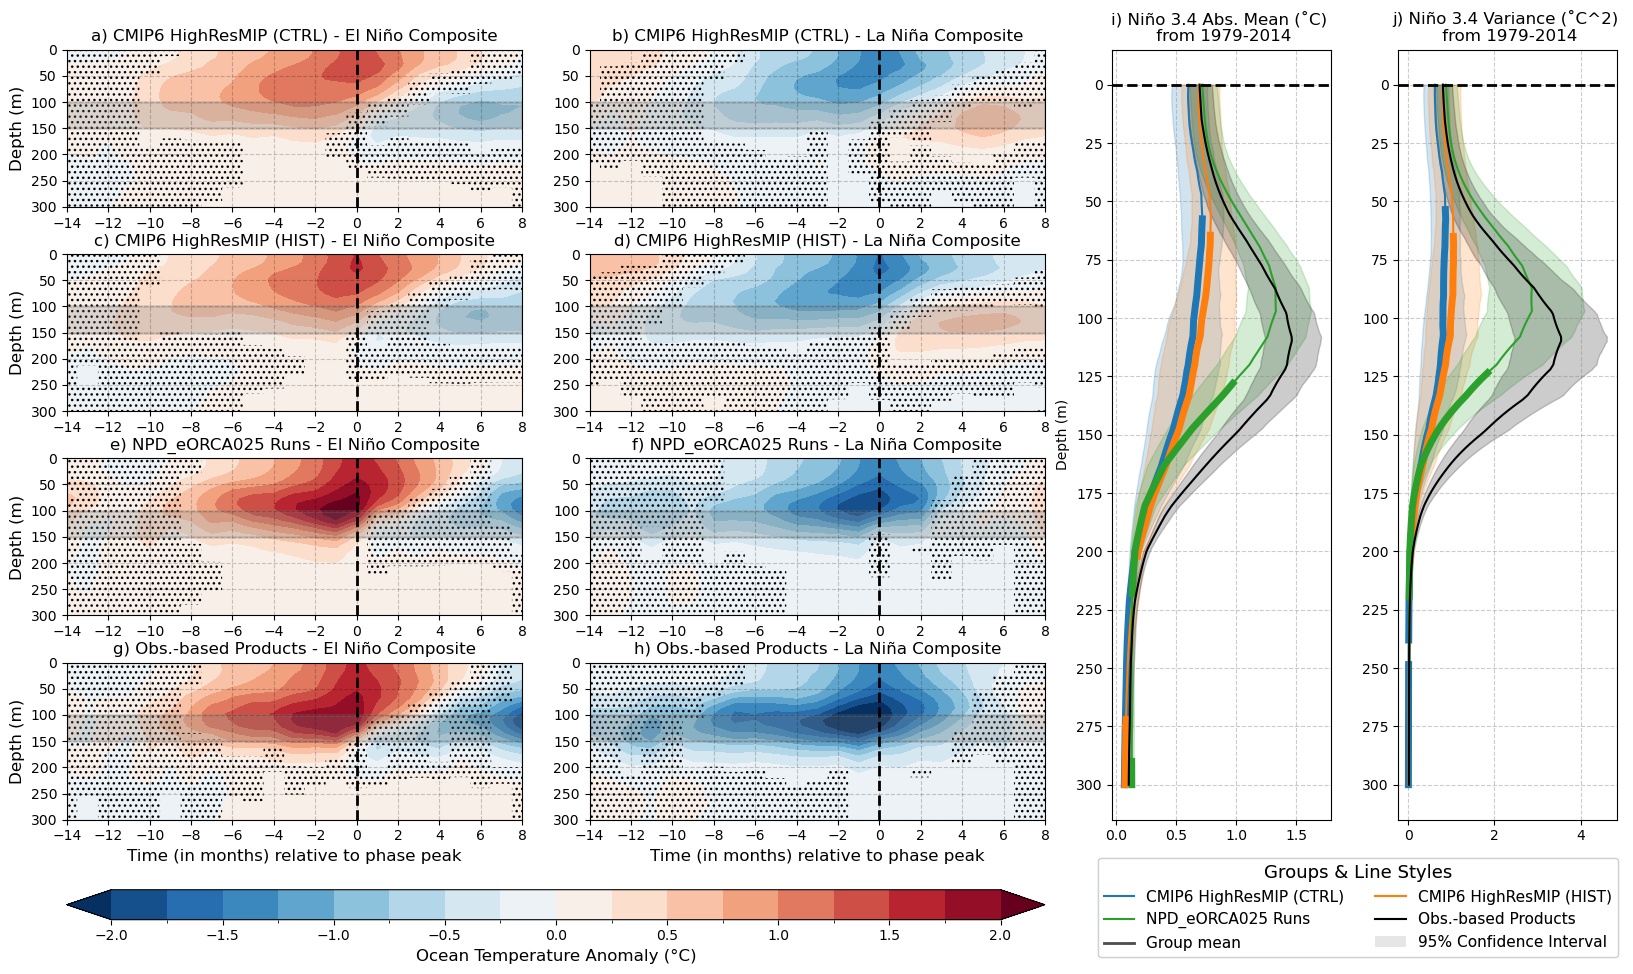

In [19]:
# =============================================================================
# CONFIGURING THE FIGURE AND GRID SPECIFICATIONS
# =============================================================================
fig = plt.figure(figsize=(20, 10))

# 4 rows, 4 columns:
#   columns 0-1: 4x2 event-centred group-mean composites (rows: CTRL, HIST, NPD, OBS; columns: El Niño, La Niña)
#   columns 2-3: Niño 3.4 mean and variance profiles (one tall panel each, spanning all rows)
gs = fig.add_gridspec(nrows=4, ncols=4, width_ratios=[1.0, 1.0, 0.48, 0.48], wspace=0.20, hspace=0.30,)

# Left block (2 cols, 4 rows)
ax_event_comp = np.empty((4, 2), dtype=object)
for r in range(4):
    for c in range(2):
        ax_event_comp[r, c] = fig.add_subplot(gs[r, c])

# Right block (two vertical panels spanning all rows)
ax_n34_mean_prof = fig.add_subplot(gs[:, 2])
ax_n34_var_prof = fig.add_subplot(gs[:, 3], sharey=ax_n34_mean_prof)

# =============================================================================
# PLOTTING THE LEFT BLOCK: GROUP-MEAN EVENT-CENTRED HOVMÖLLER COMPOSITES
# =============================================================================
title_encoding = {'CTRL': 'CMIP6 HighResMIP (CTRL)', 'HIST': 'CMIP6 HighResMIP (HIST)', 'NPD': 'NPD_eORCA025 Runs', 'OBS': 'Obs.-based Products'}    
                  
for idx, _ in enumerate(['CTRL', 'HIST', 'NPD', 'OBS']):
    # Composites ('M': group mean, 'sig': cross-dataset significance agreement mask) of this group
    ds_comp = ENSO_N34_HOV_EVENT_COMPOSITE.sel(comp = _)

    # El Niño event-centred composites + cross-dataset significance agreement mask
    ds_comp['M'].sel(phase = 'EL-NINO').transpose().plot.contourf(yincrease=False, ax=ax_event_comp[idx, 0],
                                                                  levels=np.arange(-2, 2.1, 0.25), add_colorbar=False, extend='both')

    # Add the significance agreement mask
    c_hatch1 = ax_event_comp[idx, 0].contourf(ENSO_N34_HOV_EVENT_COMPOSITE.time, ENSO_N34_HOV_EVENT_COMPOSITE.depth,
                                              ds_comp['sig'].sel(phase = 'EL-NINO').transpose(),
                                              levels = [-0.5, 0.5], hatches = ['...'], colors="none")
    c_hatch1._hatch_color = color_shade

    # La Niña event-centred composites + cross-dataset significance agreement mask
    cbar_left_block = ds_comp['M'].sel(phase = 'LA-NINA').transpose().plot.contourf(yincrease=False, ax=ax_event_comp[idx, 1],
                                                                                    levels=np.arange(-2, 2.1, 0.25), add_colorbar=False,
                                                                                    extend='both')
    c_hatch2 = ax_event_comp[idx, 1].contourf(ENSO_N34_HOV_EVENT_COMPOSITE.time, ENSO_N34_HOV_EVENT_COMPOSITE.depth,
                                              ds_comp['sig'].sel(phase = 'LA-NINA').transpose(),
                                              levels = [-0.5, 0.5], hatches = ['...'], colors="none")
    c_hatch2._hatch_color = color_shade

    ax_event_comp[idx, 0].set_title(f'{chr(ord('a') + 2*idx)}) {title_encoding[_]} - El Niño Composite', fontsize=12)
    ax_event_comp[idx, 1].set_title(f'{chr(ord('a') + 2*idx + 1)}) {title_encoding[_]} - La Niña Composite', fontsize=12)

# =============================================================================
# PLOTTING THE RIGHT BLOCK: GROUP-MEAN MEAN AND VARIANCE NIÑO 3.4 PROFILES
# =============================================================================

# Plotting group-mean Niño 3.4 mean and variance profiles for the full time series, with the 95% CI of the bootstrap (shading).
# The thick line marks the depths where the group differs significantly from OBS (p < 0.05)
for c, group in zip(['C0', 'C1', 'C2', 'k'], ['HighResMIP-CTRL', 'HighResMIP-HIST', 'NPD', 'OBS']):
    ci_lo = group_n34_stats[['mean_boot', 'var_boot']].sel(group = group).quantile(q=0.025, dim='boot')
    ci_hi = group_n34_stats[['mean_boot', 'var_boot']].sel(group = group).quantile(q=0.975, dim='boot')
    sig = group_n34_stats[['pval_mean', 'pval_var']].sel(group = group) < 0.05
    ax_n34_mean_prof.plot(group_n34_stats['mean'].sel(group = group),group_n34_stats['depth'], color = c, label = title_encoding[group.split('-')[-1]], lw = 1.5)
    ax_n34_mean_prof.plot(group_n34_stats['mean'].sel(group = group).where(sig['pval_mean']),group_n34_stats['depth'], color = c, lw = 5)
    ax_n34_mean_prof.fill_betweenx(y = group_n34_stats['mean'].depth, x1 = ci_lo['mean_boot'], x2 = ci_hi['mean_boot'], color = c, alpha = 0.2)

    ax_n34_var_prof.plot(group_n34_stats['var'].sel(group = group), group_n34_stats['depth'], color = c, label = title_encoding[group.split('-')[-1]], lw = 1.5)
    ax_n34_var_prof.plot(group_n34_stats['var'].sel(group = group).where(sig['pval_var']),group_n34_stats['depth'], color = c, lw = 5)
    ax_n34_var_prof.fill_betweenx(y = group_n34_stats['var'].depth, x1 = ci_lo['var_boot'], x2 = ci_hi['var_boot'], color = c, alpha = 0.2)

ax_n34_mean_prof.set_title(f'i) Niño 3.4 Abs. Mean (˚C) \n from {PERIOD_LABEL.split('_')[-1]}')
ax_n34_var_prof.set_title(f'j) Niño 3.4 Variance (˚C^2) \n from {PERIOD_LABEL.split('_')[-1]}')

# =============================================================================
# AXES STYLING AND GUIDE LINES
# =============================================================================
# Formatting for left block
for i, ax in enumerate(flatten(ax_event_comp)):
    ax_idx = np.argwhere(ax_event_comp == ax)[0]
    last_row = True if ax_idx[0] == (ax_event_comp.shape[0] - 1) else False
    format_axis(ax, kind = 'event_comp', i = i, last_row = last_row)
    
# Formatting for right block
for ax in [ax_n34_mean_prof, ax_n34_var_prof]:
    ax.set_yticks(np.arange(0, 300.1, 25))
    ax.grid(True, color='gray', ls='--', alpha=0.4)
    ax.axhline(0, ls='--', color='k', lw=2)
    ax.set_xlabel('')
ax.invert_yaxis()
# Show y-label only on the left of the right block
ax_n34_mean_prof.set_ylabel('Depth (m)')
 
# =============================================================================
# LEGEND ITEMS FOR RIGHT BLOCK SUBPLOTS
# =============================================================================
handles_all, labels_all = [], []
for ax in [ax_n34_mean_prof, ax_n34_var_prof]:
    h, l = ax.get_legend_handles_labels()
    for hh, ll in zip(h, l):
        if ll not in labels_all:
            handles_all.append(hh)
            labels_all.append(ll)

# Add the style handles to the same list
mean_handle   = Line2D([0], [0], color='0.3', lw=2, label='Group mean')
spread_handle = Patch(facecolor='0.6', edgecolor='none', alpha=0.2, label='95% Confidence Interval')
handles_all += [mean_handle, spread_handle]
labels_all += ['Group mean', '95% Confidence Interval']

# Reorder (the legend fills column by column): left column = CTRL, NPD, Group mean
#                                              right column = HIST, OBS, 95% Confidence Interval
# Original handles_all order: [CTRL, HIST, NPD, OBS]
ordered_handles = [handles_all[0], handles_all[2], mean_handle,
                   handles_all[1], handles_all[3], spread_handle]
ordered_labels  = [labels_all[0],  labels_all[2],  'Group mean',
                   labels_all[1],  labels_all[3],  '95% Confidence Interval']

leg_combined = fig.legend(ordered_handles, ordered_labels, loc='lower right', title = 'Groups & Line Styles',
                                       ncols=2, frameon=True, fontsize=11, title_fontsize = 13, bbox_to_anchor=(0.9044, -0.035))
fig.add_artist(leg_combined)

# =============================================================================
# SHARED COLORBAR FOR LEFT BLOCK SUBPLOTS
# =============================================================================

add_colorbar(fig, axes = list(ax_event_comp.flatten()), mappable = cbar_left_block,
             label = 'Ocean Temperature Anomaly (°C)', ticks=np.arange(-2, 2.1, 0.5), 
             side = 'bottom',  height=0.030, pad = 0.1, labelsize = 12, ticksize = 10)

# Tight layout after legends and colourbar
fig.tight_layout(rect=(0.04, 0.09, 0.98, 0.98))
fig.savefig(f'{FIG_DIR}figure_5.png', bbox_inches = 'tight', dpi = 300)

### Figure 6: Vertical profile of temperature extremes characterizing ENSO (from composites)

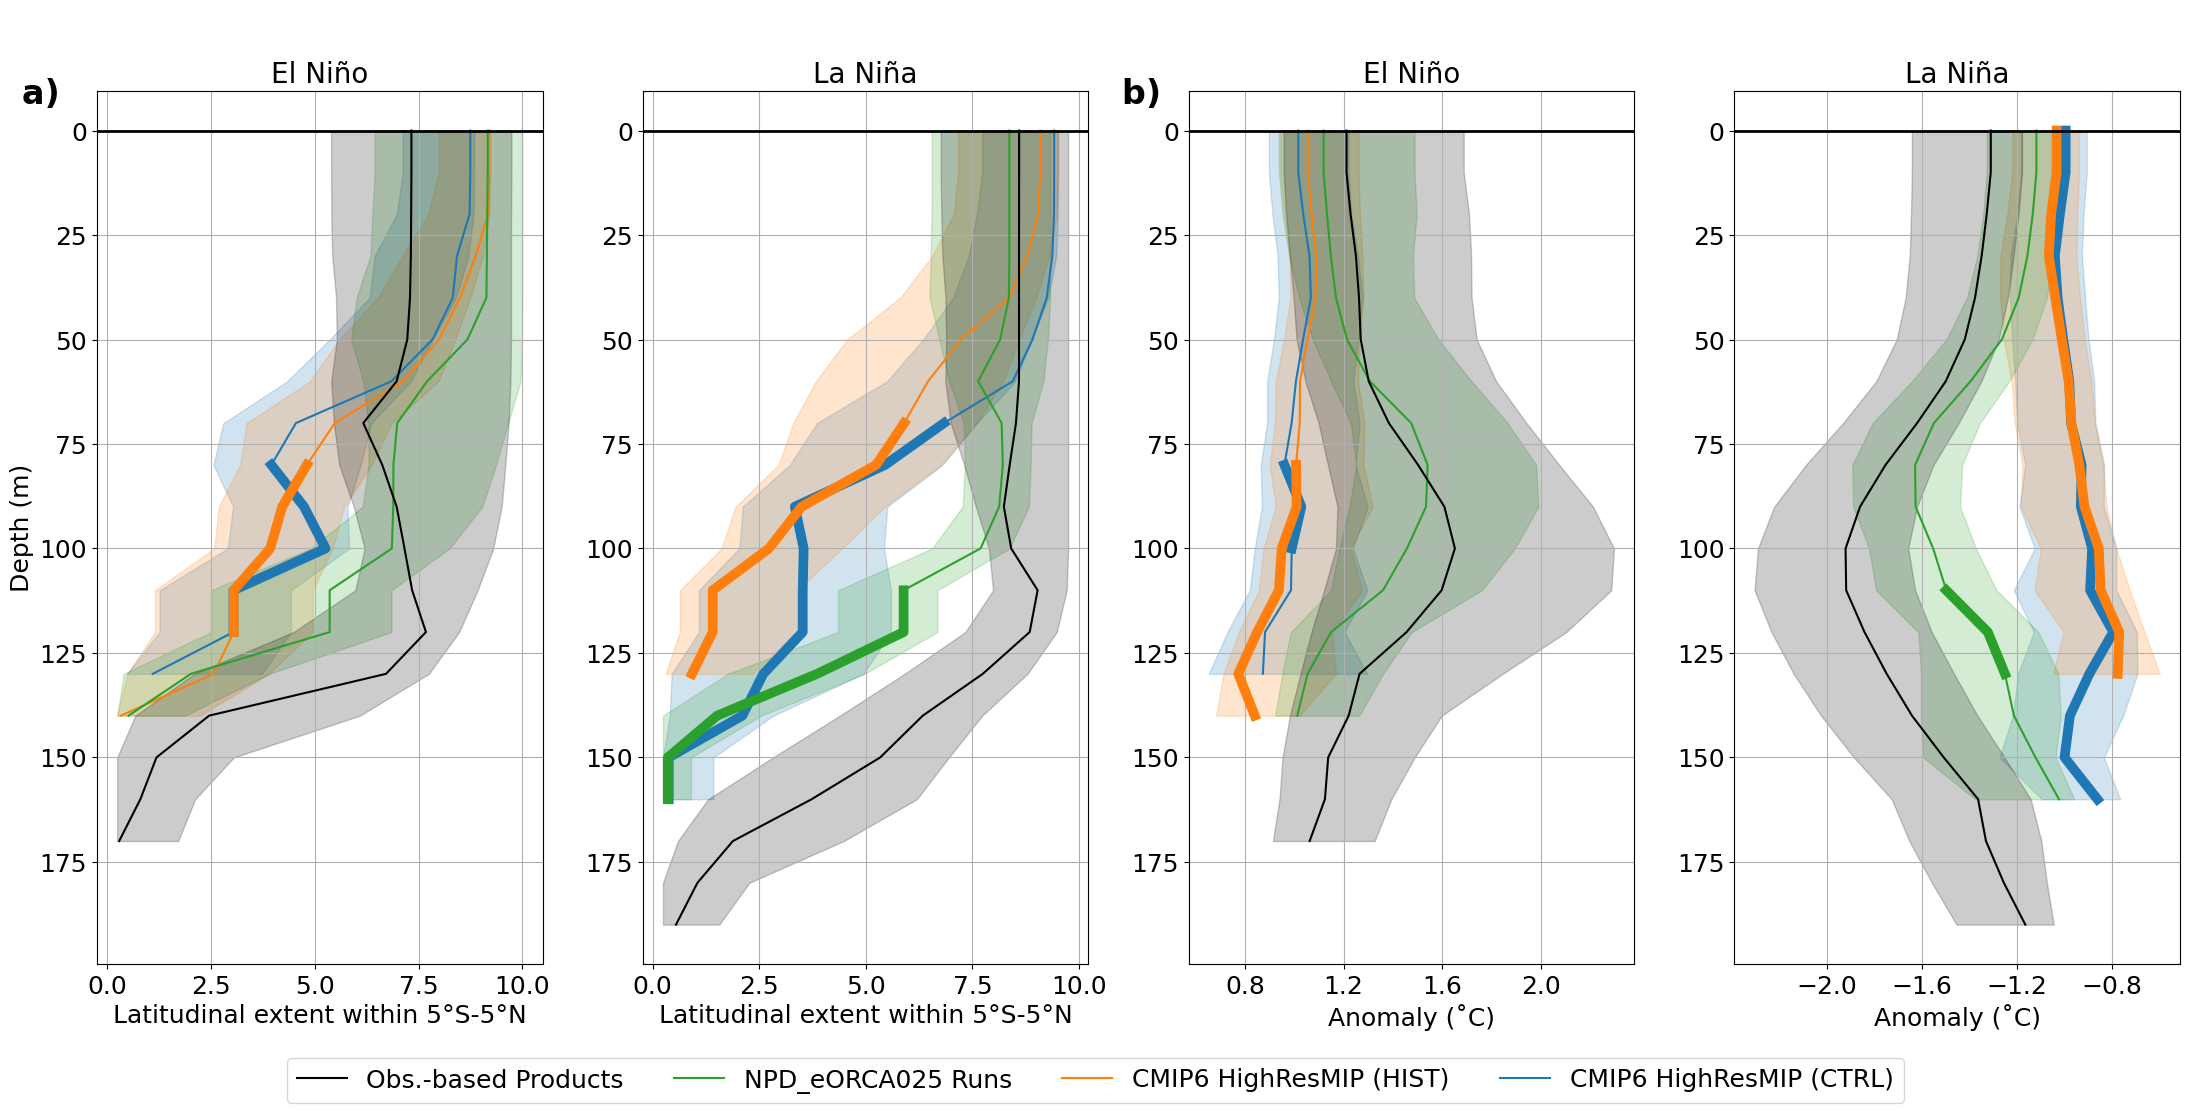

In [ ]:
# Reading in the bootstrapped datasets (written by appendices/appendix_A.ipynb) for the masked temperature extremes (EXTENT and
# INTENSITY) of each group and ENSO phase: the group mean (BOOTSTRAP_DIR) and the difference to OBS (BOOTSTRAP_DIR_BIAS)

# =============================================================================
# PLOTTING VERTICAL PROFILE OF MASKED TEMPERATURE EXTREMES
# =============================================================================
fig, ax = plt.subplots(1,4, figsize = (22,10), sharey = True)
label_encoding = {'CTRL': 'CMIP6 HighResMIP (CTRL)', 'HIST': 'CMIP6 HighResMIP (HIST)', 'NPD': 'NPD_eORCA025 Runs', 'OBS': 'Obs.-based Products'}    

for group, C in zip(['CTRL', 'HIST', 'NPD', 'OBS'], ['C0', 'C1', 'C2', 'k']):
    # One dataset per ENSO phase: columns of ax are (EXTENT: EN, LN | INTENSITY: EN, LN)
    ext_prof = {phase: xr.open_dataset(glob.glob(BOOTSTRAP_DIR.format(label=group, phase=phase))[0]) for phase in ['EL-NINO', 'LA-NINA']}
    if group != 'OBS': # OBS group does not have a bias dataset, so skip the bias plotting for OBS
        ext_prof_bias = {phase: xr.open_dataset(glob.glob(BOOTSTRAP_DIR_BIAS.format(label=group, phase=phase))[0]) for phase in ['EL-NINO', 'LA-NINA']}
    for m, metric in enumerate(['EXTENT', 'INTENSITY']):
        for p, phase in enumerate(['EL-NINO', 'LA-NINA']):
            ds, a = ext_prof[phase], ax[2*m + p]
            M = ds['M'].sel(type=metric)
            a.plot(M.values, ds.depth.values, color=C, ls='-', label=label_encoding[group])

            if group != 'OBS': # OBS group does not have a bias dataset, so skip the bias plotting for OBS
                sig = ext_prof_bias[phase]['sig'].sel(type=metric)
                a.plot(M.where(sig).values, ds.depth.values, color=C, ls='-', lw=7) # Thick line where the difference to OBS is significant
            # Fill between the 95% confidence intervals for each group and phase
            a.fill_betweenx(ds.depth.values, ds['lo'].sel(type=metric).values, ds['hi'].sel(type=metric).values, color=C, alpha=0.2)

for i, _ in enumerate(ax):
    format_axis(ax=_, kind='vert_prof', i=i)
    _.tick_params(labelleft=True)
ax[0].invert_yaxis()
ax[0].set_title('El Niño', fontsize = 20)
ax[2].set_title('El Niño', fontsize = 20)
ax[1].set_title('La Niña', fontsize = 20)
ax[3].set_title('La Niña', fontsize = 20)
ax[1].set_ylabel('')
ax[2].set_ylabel('')
ax[3].set_ylabel('')
# =============================================================================
# LEGEND ITEMS
# =============================================================================
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes]
lines, labels = [sum(x, []) for x in zip(*lines_labels)]
# Grabbing unique labels (a set, so the legend order can vary between runs)
unique_labels = set(labels)
# Assigning labels and legends in dict
legend_dict = dict(zip(labels, lines))
# Query dict based on unique labels
unique_lines = [legend_dict[x] for x in unique_labels]
fig.legend(unique_lines, unique_labels, ncols = 5, loc = 'lower center', bbox_to_anchor=(0.5, -0.07), fontsize=18)

fig.tight_layout(w_pad = 2.5)

# Panel letters: a) EXTENT, b) INTENSITY
plt.annotate('a) ', xy = (0.01, 1.01), fontsize = 24, fontweight = 'bold', xycoords='figure fraction')
plt.annotate('b) ', xy = (0.51, 1.01), fontsize = 24, fontweight = 'bold', xycoords='figure fraction')
fig.savefig(f'{FIG_DIR}figure_6.png', bbox_inches = 'tight', dpi = 300)

## Section 3.2: Future evaluation (FUTR_EVAL: 2015-2050)

In [ ]:
# Period of Section 3.2 (Figures 7-11)
PERIOD_LABEL = PERIOD_LABELS['SCEN_F']

### Figure 7: ONI Timeseries and Niño 3.4 Power Spectra

In [22]:
# =============================================================================
# READING IN THE NIÑO 3.4 AND ONI TIME SERIES DATA
# =============================================================================
# Niño 3.4 index and ONI of the HIST (HIST_EVAL) and SCEN (FUTR_EVAL) runs (written by enso_preprocessing.py)
n34_data_hist = pd.read_csv(f"{DATA_DIR}N34_INDEX_{PERIOD_LABELS['HIST']}.csv", index_col = 0, parse_dates = True)[HIGHRESMIP_EXPS_HIST]
oni_data_hist = pd.read_csv(f"{DATA_DIR}ONI_{PERIOD_LABELS['HIST']}.csv", index_col = 0, parse_dates = True)[HIGHRESMIP_EXPS_HIST]

n34_data_scen = pd.read_csv(f'{DATA_DIR}N34_INDEX_{PERIOD_LABEL}.csv', index_col = 0, parse_dates = True)[HIGHRESMIP_EXPS_SCEN]
oni_data_scen = pd.read_csv(f'{DATA_DIR}ONI_{PERIOD_LABEL}.csv', index_col = 0, parse_dates = True)[HIGHRESMIP_EXPS_SCEN]

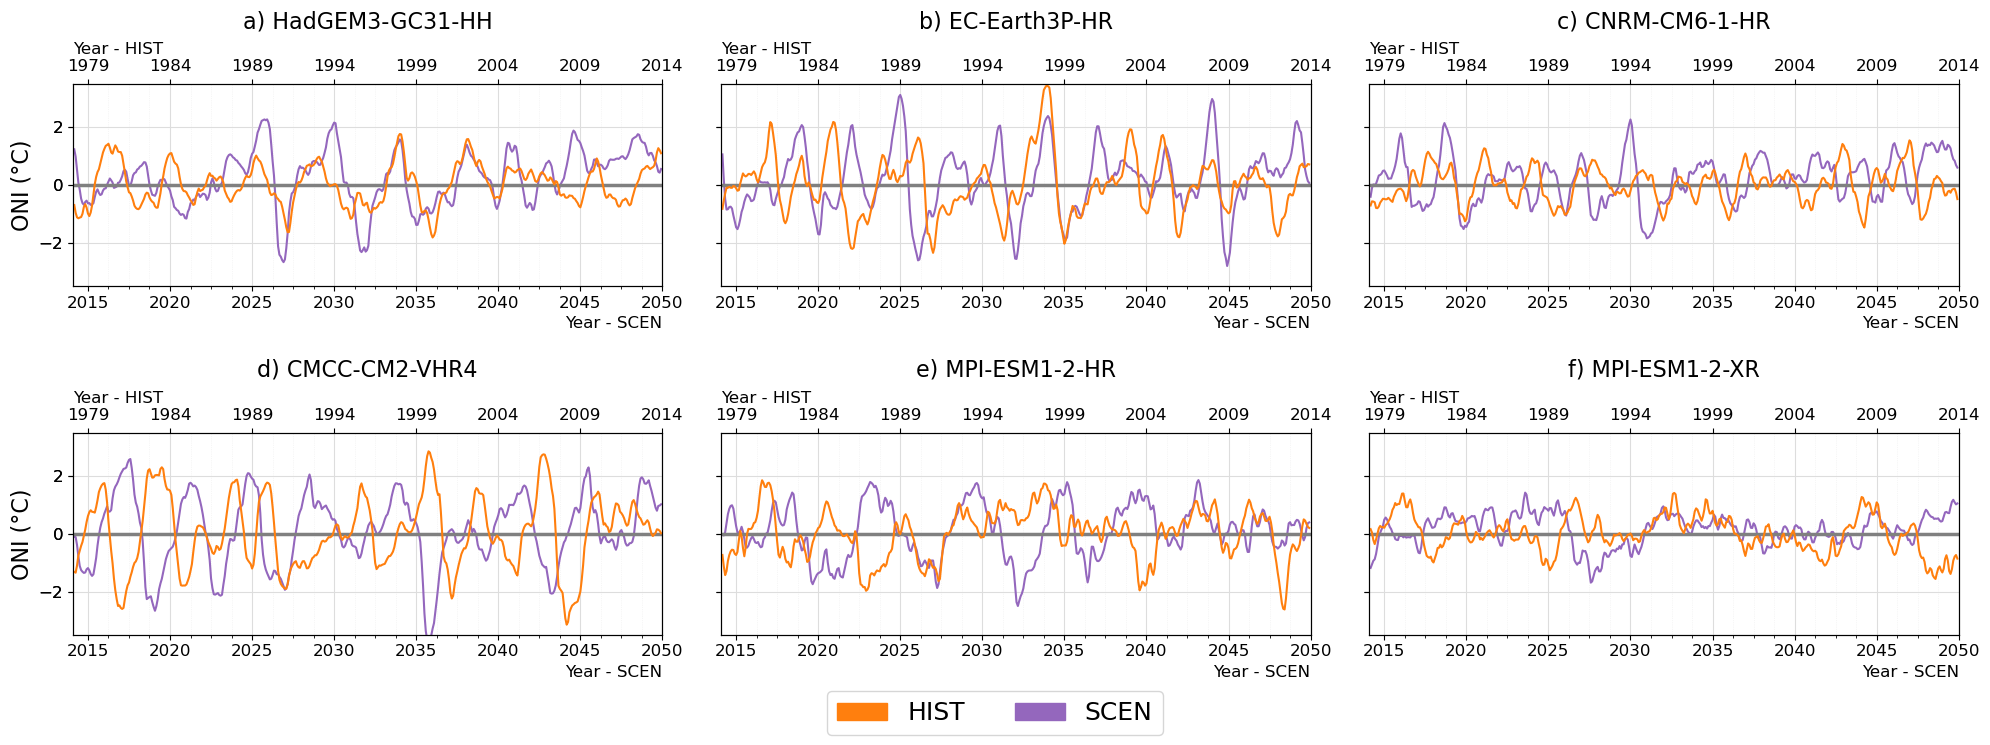

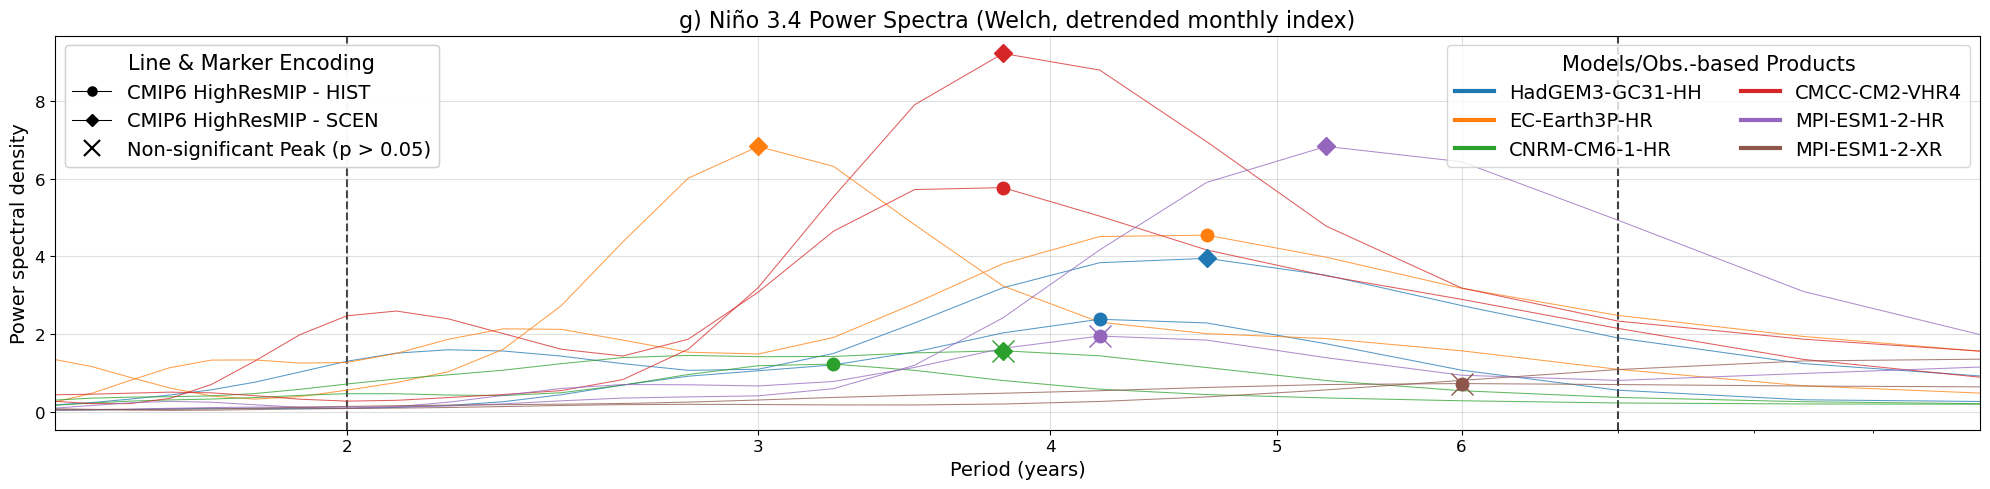

In [ ]:
# =============================================================================
# PLOTTING HIGHRESMIP_MODELS (BOTH 'HIST' AND 'SCEN')
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False, sharey=True)
axes = axes.ravel()

for i, (model, ax) in enumerate(zip(HIGHRESMIP_MODELS, axes)):
    oni_data_scen[f'{model}_SCEN'].plot(color='C4', ax=ax)
    ax_hist = ax.twiny()
    oni_data_hist[f'{model}_HIST'].plot(color='C1', ax=ax_hist)
    # Panel title
    panel_letter = chr(ord('a') + i)
    ax.set_title(f'{panel_letter}) {model}', fontsize=16, pad = 10)

    # Formatting the axes
    format_axis(ax = ax, kind = 'oni', period = PERIOD_LABELS['SCEN_F'])
    format_axis(ax = ax_hist, kind = 'oni', period = PERIOD_LABELS['HIST'], twin = True)
    ax.set_xlabel('Year - SCEN', fontsize = 12, loc = 'right')
    ax_hist.set_xlabel('Year - HIST', fontsize = 12, loc = 'left')

# Legend handles for HIST vs SCEN
legend_patches = [mpatches.Patch(color='C1', label='HIST'),
                  mpatches.Patch(color='C4', label='SCEN'),]

# Figure legend below the panels
fig.legend(handles=legend_patches, loc='lower center', fontsize=18, ncols=4, bbox_to_anchor=(0.5, -0.075))

fig.tight_layout(h_pad=2, w_pad=2)
fig.savefig(f'{FIG_DIR}figure_7_pt1.png', bbox_inches='tight', dpi=300)

# =============================================================================
# PLOTTING POWER SPECTRAL DENSITY FOR EACH DATASET
# =============================================================================
fig, ax = plt.subplots(figsize=(20, 5))
peak_points = [] # Collect peak markers to draw last

# HighResMIP models (HIST: filled circle, SCEN: filled diamond)
for base in HIGHRESMIP_MODELS:
    c = colours[base]
    for rt in ['HIST', 'SCEN']:
        colname = f'{base}_{rt}'
        line_kw = dict(linestyle='-', linewidth=0.75, color=c, alpha=0.75, zorder=2,)
        if rt == 'SCEN':
            # Filled diamond
            peak_kw = dict(marker='D', mfc=c, mec=c, mew=1.0, ms=9, zorder=12,)
            plot_psd_series(series_name = colname, n34_data = n34_data_scen, 
                        ax = ax, peak_points = peak_points, psd_kwargs = PSD_KW, 
                        line_kw = line_kw, peak_marker_kw = peak_kw, ns_lst = ns_lst)
        else:
            # Filled circle
            peak_kw = dict(marker='o', mfc=c, mec=c, mew=1.0, ms=9, zorder=12,)
            plot_psd_series(series_name = colname, n34_data = n34_data_hist, 
                        ax = ax, peak_points = peak_points, psd_kwargs = PSD_KW, 
                        line_kw = line_kw, peak_marker_kw = peak_kw, ns_lst = ns_lst)
        
# =============================================================================
# DRAWING PEAK MARKERS
# =============================================================================
for xv, yv, kw, significance in peak_points:
    ax.plot(xv, yv, linestyle='None', marker=kw['marker'], markersize=kw['ms'], 
            markerfacecolor=kw['mfc'], markeredgecolor=kw['mec'], markeredgewidth=kw['mew'], zorder=kw['zorder'],)
    if significance == False:
            ax.plot(xv, yv, linestyle='None', marker='x', markersize=16, markerfacecolor=kw['mfc'], 
                    markeredgecolor=kw['mec'], markeredgewidth=kw['mew'], zorder=20,)
    
# Axis styling (panel letter g: i = 5 after the loop over the six model panels)
format_axis(ax, kind = 'psd', panel_id = chr(ord('a') + i + 1))

# =============================================================================
# CONFIGURING LEGENDS FOR LINE COLOURS, MARKER ENCODING ETC.
# =============================================================================
# Legend 1: colour -> dataset/model
handles1 = [Line2D([0], [0], color=colours[name], lw=3) for name in HIGHRESMIP_MODELS]
labels1 = list(HIGHRESMIP_MODELS)
leg1 = ax.legend(handles1, labels1, title='Models/Obs.-based Products', 
                 loc='upper right', fontsize=14, ncol=2, title_fontsize=15,)
ax.add_artist(leg1)

# Legend 2: encoding (style/marker)
handles2 = [Line2D([0], [0], color='black', lw=0.75, ls='-', marker='o', mfc='black', mec='black', 
                   mew=1.5, label='CMIP6 HighResMIP - HIST'),
            Line2D([0], [0], color='black', lw=0.75, ls='-', marker='D', mfc='black', mec='black', 
                   label='CMIP6 HighResMIP - SCEN'),
            Line2D([0], [0], color='black', lw=1.25, ls='None', marker='x', mfc='none', mec='black', 
                               mew=1.5, ms = 12, label='Non-significant Peak (p > 0.05)')]
leg2 = ax.legend(handles2, ['CMIP6 HighResMIP - HIST', 'CMIP6 HighResMIP - SCEN', 'Non-significant Peak (p > 0.05)'], 
                 title='Line & Marker Encoding', loc='upper left', fontsize=14, title_fontsize=15,)
ax.add_artist(leg2)


fig.tight_layout()
# Saving the figure
fig.savefig(f'{FIG_DIR}figure_7_pt2.png', bbox_inches='tight', dpi=300)

In [24]:
# =============================================================================
# MERGING BOTH FIGURES ABOVE INTO A SINGLE FIGURE
# =============================================================================
merge_pngs_vertical(
    [
        f"{FIG_DIR}figure_7_pt1.png",
        f"{FIG_DIR}figure_7_pt2.png",
    ],
    f"{FIG_DIR}figure_7.png",
)

### Figure 8: Group-mean ENSO Composites, Bias and 'Flavour' Proportions

In [ ]:
# Reading in the ENSO SSTA composite xarray.Dataset (the same file as in Section 3.1, written by appendices/appendix_A.ipynb).
# SCEN_F is the full 2015-2050 scenario; SCEN_F-HIST is its difference to HIST
ENSO_COMPOSITES[PERIOD_LABEL] = xr.open_dataset(f'{DATA_DIR}ENSO_SSTA_COMP_DIFF_RESULTS_WITH_SIG.nc')

# ENSO flavour proportions of the HIST and SCEN runs (written by enso_preprocessing.py)
ENSO_FLAV_PROP_HIST = pd.read_csv(f"{DATA_DIR}ENSO_FLAVOUR_PROPORTIONS_{PERIOD_LABELS['HIST']}.csv", index_col=0)
ENSO_FLAV_PROP_SCEN = pd.read_csv(f'{DATA_DIR}ENSO_FLAVOUR_PROPORTIONS_{PERIOD_LABEL}.csv', index_col=0)
# Group medians in %: one row per group of model experiments
ENSO_FLAV_PROP_GRP_MEDIAN = pd.DataFrame([ENSO_FLAV_PROP_HIST.loc[ENSO_FLAV_PROP_HIST.index.isin(HIGHRESMIP_EXPS_HIST)].median(axis = 0).rename('HIST'),
                                          ENSO_FLAV_PROP_SCEN.loc[ENSO_FLAV_PROP_SCEN.index.isin(HIGHRESMIP_EXPS_SCEN)].median(axis = 0).rename('SCEN'),]) * 100

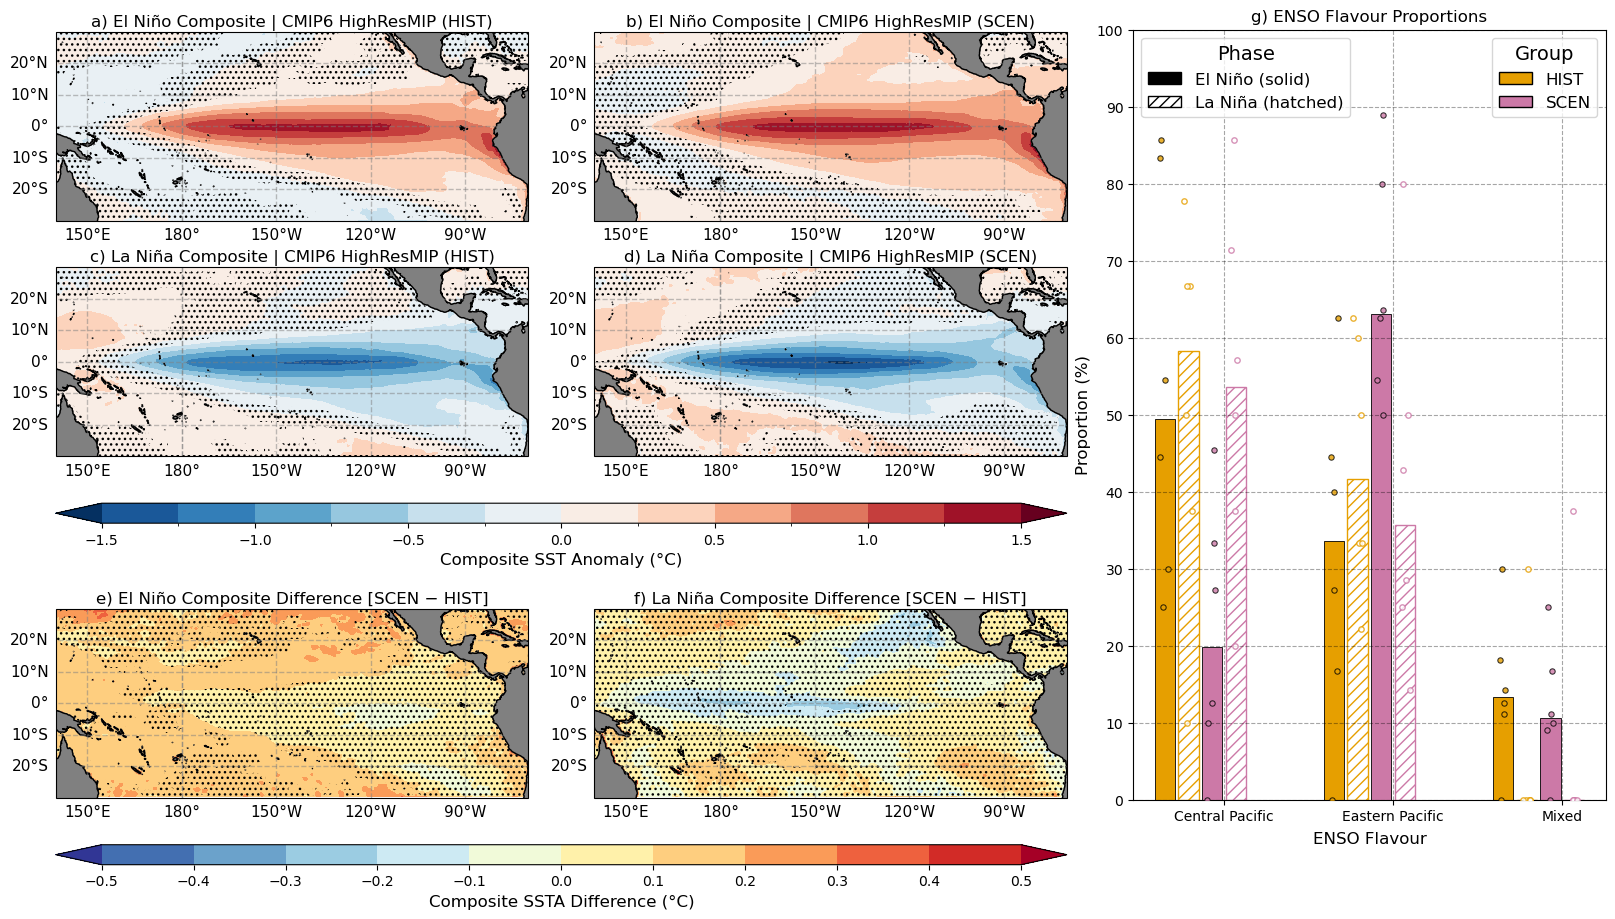

In [ ]:
# =============================================================================
# CONFIGURING THE FIGURE AND GRID SPECIFICATIONS
# =============================================================================
fig = plt.figure(figsize=(20, 10), constrained_layout=False)

# 4 rows and 3 columns:
#   rows 0-1, columns 0-1: 2x2 ENSO composite maps
#   row 2: spacer (small height)
#   row 3, columns 0-1: 1x2 difference maps
#   column 2 (all rows): flavour proportions bar chart
gs = fig.add_gridspec(nrows=4, ncols=3, height_ratios=[1.2, 1.2, 0.4, 1.2], width_ratios=[1, 1, 1], hspace=0.26, wspace=0.14)

# Left 2 columns, top 2 rows: ENSO composites
projection = ccrs.PlateCarree(central_longitude=180)
ax_enso = np.empty((2, 2), dtype=object)
for r in range(2):
    for c in range(2):
        ax_enso[r, c] = fig.add_subplot(gs[r, c], projection=projection)

# Difference axes (columns 0-1, row 3)
ax_diff = {}
ax_diff['EN_HIGHRESMIP']   = fig.add_subplot(gs[3, 0], projection=projection)
ax_diff['LN_HIGHRESMIP']   = fig.add_subplot(gs[3, 1], projection=projection)

# right-side axes spanning all rows (last column; index 2)
ax_flav_prop = fig.add_subplot(gs[:, 2])

# Contour levels and colourmaps
# composite maps
levels = np.arange(-1.5, 1.51, 0.25)
cmap_enso_composites = 'RdBu_r'

# Difference maps
levels_diff = np.arange(-0.50, 0.51, 0.10)
cmap_enso_diff = 'RdYlBu_r'

# =============================================================================
# UPPER PANELS: GROUP-MEAN COMPOSITES (2 columns × 2 rows)
# =============================================================================
group_order = ['HIST', 'SCEN_F']

en_titles = ['a) El Niño Composite | CMIP6 HighResMIP (HIST)',
             'b) El Niño Composite | CMIP6 HighResMIP (SCEN)',]
ln_titles = ['c) La Niña Composite | CMIP6 HighResMIP (HIST)',
             'd) La Niña Composite | CMIP6 HighResMIP (SCEN)',]

mappable_enso = None

# Row 0: El Niño composites; row 1: La Niña composites (one column per group)
for row, (varname, titles) in enumerate([('EL-NINO', en_titles), ('LA-NINA', ln_titles)]):
    for col, (group_key, title) in enumerate(zip(group_order, titles)):
        ds_grp = ENSO_COMPOSITES[PERIOD_LABEL].sel(comp = group_key).squeeze()
        ds_phase = ds_grp.sel(phase = varname).squeeze()
        da = ds_phase['M']
        da_sig = ds_phase['sig']

        mappable_enso = da.plot.contourf(ax=ax_enso[row, col], transform=ccrs.PlateCarree(), x='lon', y='lat', 
                                         cmap=cmap_enso_composites, add_colorbar=False, levels=levels, extend='both')
        c_hatch = ax_enso[row, col].contourf(da_sig.lon, da_sig.lat, da_sig.astype(float), levels=[-0.5, 0.5], hatches=['...'], 
                                                     colors='none', transform=ccrs.PlateCarree())
        # Customising the hatch/stipple colour
        c_hatch._hatch_color = color_shade

        format_axis(ax = ax_enso[row, col], kind = 'map', land_ft = land_50m, coast_ft = coast_50m)
        ax_enso[row, col].set_title(title, fontsize=12, pad=4)

# =============================================================================
# LOWER LEFT: DIFFERENCE MAPS (2 columns × 1 row)
# =============================================================================
mappable_diff = None

# SCEN_F - HIST differences
for varname, ax_key, title in [('EL-NINO', 'EN_HIGHRESMIP', 'e) El Niño Composite Difference [SCEN − HIST]'),
                               ('LA-NINA', 'LN_HIGHRESMIP', 'f) La Niña Composite Difference [SCEN − HIST]'),]:
    ds_diff = ENSO_COMPOSITES[PERIOD_LABEL].sel(comp = 'SCEN_F-HIST', phase = varname).squeeze()
    da_diff = ds_diff['D']
    da_diff_sig = ds_diff['sig']
    mappable_diff = da_diff.plot.contourf(ax=ax_diff[ax_key], transform=ccrs.PlateCarree(), x='lon', y='lat', 
                                          cmap=cmap_enso_diff, add_colorbar=False, levels=levels_diff, extend='both')
    c_hatch = ax_diff[ax_key].contourf(da_diff_sig.lon, da_diff_sig.lat, da_diff_sig.astype(float), levels=[-0.5, 0.5], 
                                       hatches=['...'], colors='none', transform=ccrs.PlateCarree())
    # Customising the hatch/stipple colour
    c_hatch._hatch_color = color_shade
    
    format_axis(ax = ax_diff[ax_key], kind = 'map', land_ft = land_50m, coast_ft = coast_50m)
    ax_diff[ax_key].set_title(title, fontsize=12, pad=4)

# =============================================================================
# ENSO FLAVOUR PROPORTION BARCHART (RIGHT HAND SIDE, SPANNING ALL ROWS)
# =============================================================================
# order of the bars within each flavour: the El Niño (EN) and La Niña (LN) bar of HIST and SCEN
order = [('EN', 'HIST'), ('LN', 'HIST'),
         ('EN', 'SCEN'), ('LN', 'SCEN'),]

# Bar chart config
colours_grp = {'HIST': '#E69F00', # Orange
               'SCEN': '#CC79A7',} # Purple

# Individual datasets of each group, selected by their names in the index of the proportion tables
raw_subsets = {'HIST': ENSO_FLAV_PROP_HIST[ENSO_FLAV_PROP_HIST.index.str.contains('HIST')],
               'SCEN': ENSO_FLAV_PROP_SCEN[ENSO_FLAV_PROP_SCEN.index.str.contains('SCEN')]}

x, bar_width, gap = np.arange(len(flavours)), 0.12, 0.02

for i, (phase, grp) in enumerate(order):
    offsets = (-2.5 * bar_width - 2.5 * gap) + i * (bar_width + gap)
    xpos = x + offsets

    # CSV columns of this phase, and the group median of each
    cols_to_plot = [col_map[phase][f] for f in flavours]
    vals = [ENSO_FLAV_PROP_GRP_MEDIAN.loc[grp, col] for col in cols_to_plot]
    if phase == 'EN':
        # El Niño: filled bars
        ax_flav_prop.bar(xpos, vals, width=bar_width, color=colours_grp[grp], edgecolor='black', linewidth=0.6)
    else:
        # La Niña: hatched bars
        ax_flav_prop.bar(xpos, vals, width=bar_width, color='none', edgecolor=colours_grp[grp], hatch=hatch_style, linewidth=1.0)

    raw_subset = raw_subsets[grp]

    # Scatter the individual points
    for j, col in enumerate(cols_to_plot):
        # Multiply by 100 to convert the fractions to percentages
        y_vals = raw_subset[col].dropna().values * 100
        x_vals = np.full(len(y_vals), xpos[j])
        
        # Unseeded jitter to prevent overlapping data points (differs from run to run)
        jitter_vals = np.random.uniform(-bar_width/4, bar_width/4, size=len(y_vals),)
        
        if 'EN' in col:
            ax_flav_prop.scatter(x_vals + jitter_vals, y_vals, color=colours_grp[grp], edgecolor='black', linewidth=0.75,s=15, alpha=0.8, zorder=3)
        elif 'LN' in col:
            ax_flav_prop.scatter(x_vals + jitter_vals, y_vals, color='white', edgecolor=colours_grp[grp], linewidth=1,s=15, alpha=0.8, zorder=3)

# Axes of the bar chart
ax_flav_prop.set_xticks(x)
ax_flav_prop.set_xticklabels(['Central Pacific', 'Eastern Pacific', 'Mixed'], fontsize=10)
ax_flav_prop.set_yticks(np.arange(0, 101, 10))
ax_flav_prop.set_xlabel('ENSO Flavour', fontsize=12, labelpad=6)
ax_flav_prop.set_ylabel('Proportion (%)', fontsize=12)
ax_flav_prop.grid(visible = True, ls = '--', alpha = 0.35, color = 'k')
ax_flav_prop.set_ylim(0, 100)
ax_flav_prop.set_title('g) ENSO Flavour Proportions', fontsize=12)
ax_flav_prop.tick_params(axis='both', labelsize=10)

# Legend 1: groups (colours_grp) - upper right
group_handles = [mpatches.Patch(facecolor=colours_grp[g], edgecolor='black', label=g)for g in colours_grp]
legend_groups = ax_flav_prop.legend(handles=group_handles, title='Group',loc='upper right', fontsize=12, title_fontsize=14)

# Legend 2: phase (bar style in black) - upper left
phase_handles = [mpatches.Patch(facecolor='black', edgecolor='black', label='El Niño (solid)'), 
                 mpatches.Patch(facecolor='none', edgecolor='black', hatch=hatch_style, label='La Niña (hatched)')]
ax_flav_prop.legend(handles=phase_handles, title='Phase', loc='upper left', fontsize=12, title_fontsize=14)

# Keeping both legends (a second legend() call replaces the first, which is therefore re-added as an artist)
ax_flav_prop.add_artist(legend_groups)

# =============================================================================
# SHARED COLOURBARS
# =============================================================================

# Shared horizontal colourbar for ENSO composites
enso_axes_all = list(ax_enso[0, :]) + list(ax_enso[1, :])
add_colorbar(fig, axes = enso_axes_all, mappable = mappable_enso,
             label = 'Composite SST Anomaly (°C)', ticks=np.arange(-1.5, 1.51, 0.5), side = 'bottom', 
             height=0.020, pad = 0.065, labelsize = 12, ticksize = 10)

# Shared horizontal colourbar for diff maps
diff_axes = [ax_diff['EN_HIGHRESMIP'], ax_diff['LN_HIGHRESMIP']]
add_colorbar(fig, axes = diff_axes, mappable = mappable_diff,
             label = 'Composite SSTA Difference (°C)', ticks=levels_diff, side = 'bottom', 
             height=0.020, pad = 0.065, labelsize = 12, ticksize = 10)
# Saving the figure
fig.savefig(f'{FIG_DIR}figure_8.png', bbox_inches='tight', dpi=300)

### Figure 9: KDE of peak ENSO SST anomaly positions

In [8]:
# =============================================================================
# READING IN THE GAUSSIAN KDE DATA FOR |SST|_MAX ANOMALY POSITIONS
# =============================================================================
# KDEs (written by enso_preprocessing.py) of the FUTR_EVAL file (the 6 SCEN runs) and the HIST_EVAL file (16 datasets: CTRL, HIST,
# NPD and OBS), joined along 'dataset'
gaussian_kde_combined = xr.concat([xr.open_dataset(f"{DATA_DIR}GAUSS_KDE_5S5N_{PERIOD_LABELS['SCEN_F']}.nc"),
                                   xr.open_dataset(f"{DATA_DIR}GAUSS_KDE_5S5N_{PERIOD_LABELS['HIST']}.nc")], dim='dataset')

# =============================================================================
# GROUP-MEAN KDEs (AVERAGED ACROSS THE DATASETS IN EACH GROUP)
# =============================================================================
groups = {'CMIP6 HighResMIP (HIST)': HIGHRESMIP_EXPS_HIST,
          'CMIP6 HighResMIP (SCEN)': HIGHRESMIP_EXPS_SCEN,
          'Obs.-based Products': OBS}

gaussian_by_group = xr.concat([gaussian_kde_combined.sel(dataset=d_list).mean(dim='dataset')
                               for d_list in groups.values()], dim=pd.Index(list(groups.keys()), name='group'))


/tmp/ipykernel_3898436/484052253.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(h_pad=1.5, w_pad=1.5)


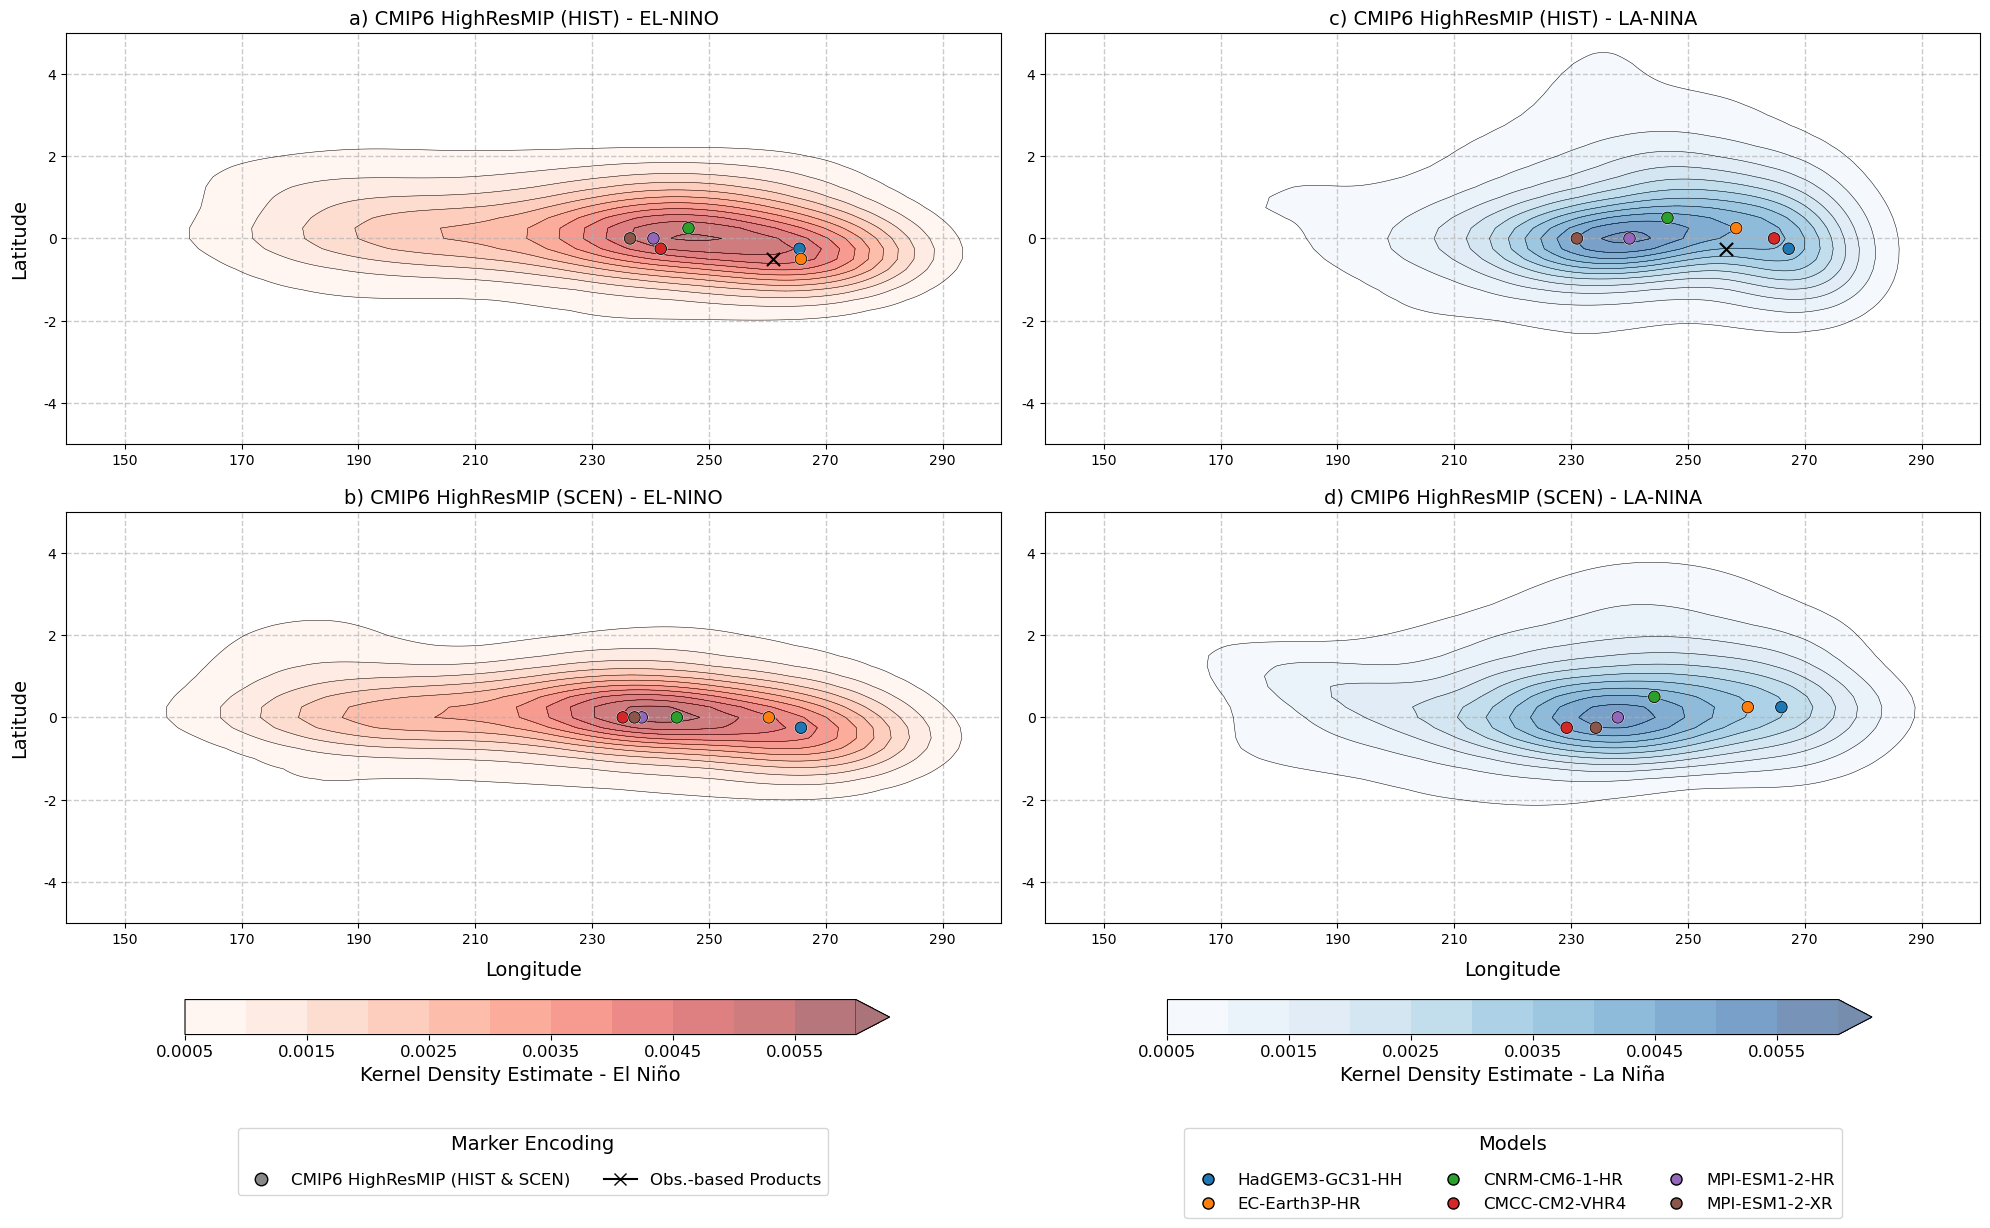

In [ ]:
# =============================================================================
# FIGURE 9: GROUP-MEAN KDEs (HIST | SCEN) - EL NIÑO (LEFT) vs LA NIÑA (RIGHT)
# =============================================================================
labels    = list(string.ascii_lowercase) # Panel labels (a, b, c, ...)
label_idx = 0 # Running panel-label counter

# Lat/lon mesh the KDEs are drawn on
lons, lats = np.meshgrid(gaussian_by_group['lon'], gaussian_by_group['lat'])
fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharex=True, sharey=True)

for enso_phase in ['EL-NINO', 'LA-NINA']:
    # Each phase gets its own colour map, column of panels (El Niño: left; La Niña: right)
    # and horizontal offset of its colourbar
    if enso_phase == 'EL-NINO':
        color_map = 'Reds'
        axes_lst = [axes[0,0], axes[1,0]]
        cbar_x_loc_adj = -0.03
        title_label = 'El Niño'
    else:
        color_map = 'Blues'
        axes_lst = [axes[0,1], axes[1,1]]
        cbar_x_loc_adj = 0.0385
        title_label = 'La Niña'

    for i, (group, ax) in enumerate(zip(['CMIP6 HighResMIP (HIST)', 'CMIP6 HighResMIP (SCEN)'], axes_lst)):
        kde = gaussian_by_group.sel(group=group, enso_phase=enso_phase)['GAUSS_KDE']
        c = ax.contourf(lons, lats, kde, cmap=color_map, levels=levels_kde, extend='max', alpha=0.55) # Filled KDE
        ax.contour(lons, lats, kde, colors='k', levels=levels_kde, linewidths=0.35) # KDE contour lines
        ax.set_title(f'{labels[label_idx]}) {group} - {enso_phase}', fontsize=14)
        format_axis(ax, kind='kde')
        # Axis labels only on the bottom row (x) and the figure's left column (y)
        ax.set_xlabel('Longitude' if i == 1 else '', fontsize=14, labelpad=10)
        ax.set_ylabel('Latitude' if (enso_phase == 'EL-NINO') else '', fontsize=14, labelpad=10)
        # Tick labels shown on every panel despite the shared axes
        ax.tick_params(left=True, labelleft=True)
        ax.tick_params(bottom=True, labelbottom=True)
        label_idx += 1

    # KDE peak of the Obs.-based group mean, marked with an 'x' on the HIST panel
    lon_o, lat_o = peak_lonlat(gaussian_by_group.sel(group='Obs.-based Products', enso_phase=enso_phase)['GAUSS_KDE'])
    axes_lst[0].scatter(lon_o, lat_o, marker='x', color='k', s=90, label='Obs.-based Products')

    # KDE peak of each HighResMIP model (circles) on the HIST and SCEN panels
    for mod in HIGHRESMIP_MODELS:
        # HIST peak
        lon_h, lat_h = peak_lonlat(gaussian_kde_combined.sel(dataset=mod + '_HIST', enso_phase=enso_phase)['GAUSS_KDE'])
        axes_lst[0].scatter(lon_h, lat_h, marker='o', s=70, facecolor=colours[mod], edgecolor='k', label=mod,
                            linewidth=0.6, zorder=6, path_effects=[pe.withStroke(linewidth=1.2, foreground='white')])

        # SCEN peak
        lon_s, lat_s = peak_lonlat(gaussian_kde_combined.sel(dataset=mod + '_SCEN', enso_phase=enso_phase)['GAUSS_KDE'])
        axes_lst[1].scatter(lon_s, lat_s, marker='o', s=70, facecolor=colours[mod], edgecolor='k',
                            linewidth=0.6, zorder=6, path_effects=[pe.withStroke(linewidth=1.2, foreground='white')])

    # Horizontal colourbar below this phase's column of panels
    height = 0.035
    pad = 0.15
    row_box = Bbox.union([ax.get_position(fig).frozen() for ax in axes_lst]) # Bounding box of the phase's panels
    cax = fig.add_axes([row_box.x0 + cbar_x_loc_adj, row_box.y0 - pad, row_box.width, height])
    cb = fig.colorbar(c, cax=cax, orientation='horizontal', ticks=list(np.arange(0.0005, 0.0065, 0.001)))
    cb.set_label(f'Kernel Density Estimate - {title_label}', fontsize=14)
    cb.ax.tick_params(labelsize=12)

# Figure legends below the panels (proxy artists)
# Legend 1: Models (colours)
color_handles = [Line2D([0], [0], marker='o', color='w', label=name, markerfacecolor=colours[name],
                        markeredgecolor='k', markersize=8) for name in HIGHRESMIP_MODELS]
leg1 = fig.legend(handles=color_handles, loc='upper center', bbox_to_anchor=(0.759, -0.125), ncols=3,
                  frameon=True, fontsize=12, title='Models')
leg1.get_title().set_fontsize(14)
leg1._legend_box.sep = 14

# Legend 2: Marker encoding (which marker shape stands for which kind of dataset)
style_handles = [Line2D([0], [0], marker='o', color='w', label='CMIP6 HighResMIP (HIST & SCEN)',
                        markerfacecolor='#888', markeredgecolor='k', markersize=9),
                 Line2D([0], [0], marker='x', color='k', label='Obs.-based Products', markersize=9)]
leg2 = fig.legend(handles=style_handles, loc='upper center', bbox_to_anchor=(0.269, -0.125), ncols=2,
                  frameon=True, fontsize=12, title='Marker Encoding')
leg2.get_title().set_fontsize(14)
leg2._legend_box.sep = 14

fig.tight_layout(h_pad=1.5, w_pad=1.5)
# Saving the figure
fig.savefig(f'{FIG_DIR}figure_9.png', bbox_inches='tight', dpi=300)

### Figure 10: Event-centred group-mean composites of vertical temperature anomalies

In [ ]:
# =============================================================================
# READING IN THE NIÑO 3.4 HOVMÖLLER EVENT COMPOSITES AND DATA
# =============================================================================
# Event-centred composites and differences (variables M, D and sig) written by appendices/appendix_A.ipynb
ENSO_N34_HOV_EVENT_COMPOSITE = xr.open_dataset(f'{DATA_DIR}ENSO_N34_HOV_COMP_DIFF_RESULTS_WITH_SIG.nc')

# Niño 3.4 temperature anomalies of the top 300 m, dims (dataset, time, depth), written by enso_preprocessing.py: the HIST runs
# for HIST_EVAL and the SCEN runs for FUTR_EVAL
N34_HOV_ZVT = {'HIST': xr.open_dataset(f"{DATA_DIR}N34_HOV_ZVT_TOP300M_{PERIOD_LABELS['HIST']}.nc").sel(dataset = HIGHRESMIP_EXPS_HIST),
               'SCEN': xr.open_dataset(f"{DATA_DIR}N34_HOV_ZVT_TOP300M_{PERIOD_LABELS['SCEN_F']}.nc").sel(dataset = HIGHRESMIP_EXPS_SCEN)}

# Calculating the mean and variance across the time axis for each dataset, followed by a group-mean operation
ACTUAL_STATS = {'HIST': xr.merge([abs(N34_HOV_ZVT['HIST']['anomaly']).mean(dim = ['time']).rename('mean'),
                                  N34_HOV_ZVT['HIST']['anomaly'].var(dim = ['time']).rename('var')]).mean(dim = 'dataset'),
                'SCEN': xr.merge([abs(N34_HOV_ZVT['SCEN']['anomaly']).mean(dim = ['time']).rename('mean'),
                                  N34_HOV_ZVT['SCEN']['anomaly'].var(dim = ['time']).rename('var')]).mean(dim = 'dataset')}

# =============================================================================
# BLOCK BOOTSTRAP OF THE HIST AND SCEN GROUP-MEAN NIÑO 3.4 MEAN AND VARIANCE PROFILES
# =============================================================================
# Two-level block bootstrap as in Figure 5 (BLOCK_SIZE and N_SIM are set in the constants cell). In every iteration the same resampled
# model indices are used for HIST and SCEN, which keeps the two groups paired by model
rng = np.random.default_rng(seed=42) # For reproducibility (not the seeds of appendix_A.ipynb)
boot_stats = {'HIST': [], 'SCEN': []}
for b in tqdm(range(N_SIM), desc = 'Bootstrapping'): # Looping through each bootstrap simulation
    full_ds = {'HIST': [], 'SCEN': []}
    # Resampled model indices (with replacement; 6 models), shared by HIST and SCEN
    m = rng.integers(0,len(HIGHRESMIP_EXPS_CTRL), size = len(HIGHRESMIP_EXPS_CTRL))
    for label in ['HIST', 'SCEN']: # Looping through each group of model experiments
        resampled_ds = N34_HOV_ZVT[label].isel(dataset = m)
        for _ in range(resampled_ds['dataset'].shape[0]):
            da = resampled_ds.isel(dataset = [_]).anomaly 
            # Reshaping the data array into blocks of size BLOCK_SIZE along the 'time' dimension
            da_reshaped = da.values.reshape(da.shape[0], da.shape[1] // BLOCK_SIZE, BLOCK_SIZE, da.shape[-1])
            # Resampling the blocks with replacement along the second dimension (blocks)
            block_indices = rng.integers(0, da_reshaped.shape[1], size=da_reshaped.shape[1])
            da_resampled = da_reshaped[:, block_indices, :, :]
            # Reshaping the resampled blocks back into the original shape
            da_resampled = da_resampled.reshape(da_reshaped.shape[0], 
                                                da_reshaped.shape[1] * da_reshaped.shape[2], 
                                                da_reshaped.shape[-1],)
            da[:] = da_resampled # Assigning the resampled data back to the original data array

            # Renaming the resampled data array and adding a new dimension for bootstrapping
            da = da.rename('anomaly_resampled').expand_dims({'boot':[b]})
            full_ds[label] += [da.to_dataset()]
            del da, da_reshaped, da_resampled, block_indices
        full_ds[label] = xr.concat(full_ds[label], dim = 'dataset')
        boot_stats[label] += [xr.merge([abs(full_ds[label]['anomaly_resampled']).mean(dim = ['time']).rename('mean_boot'),
                                        full_ds[label]['anomaly_resampled'].var(dim = ['time']).rename('var_boot')]).mean(dim = 'dataset')]
        del resampled_ds
    del full_ds, m

# Concatenating the bootstrapped mean and variance statistics for each group of model experiments along a new dimension 'boot'
boot_stats['HIST'] = xr.concat(boot_stats['HIST'], dim = 'boot')
boot_stats['SCEN'] = xr.concat(boot_stats['SCEN'], dim = 'boot')

# Concatenating the actual mean and variance statistics and the bootstrapped mean and variance statistics for each group of model experiments along a new dimension 'group'
group_n34_stats = xr.concat([xr.merge([ACTUAL_STATS[label], boot_stats[label]]).expand_dims({'group':[f'HighResMIP-{label}']}) for label in ['HIST', 'SCEN']], dim='group')

# Differences between the bootstrapped mean and variance of the SCEN and the HIST group (SCEN - HIST)
pairwise_diff = xr.merge([group_n34_stats['mean_boot'].sel(group = 'HighResMIP-SCEN') - group_n34_stats['mean_boot'].sel(group = 'HighResMIP-HIST'), 
                          group_n34_stats['var_boot'].sel(group = 'HighResMIP-SCEN') - group_n34_stats['var_boot'].sel(group = 'HighResMIP-HIST')])

# Adding the two-sided bootstrap p-values (p_val_calculation) of the differences to group_n34_stats as new variables
group_n34_stats['pval_mean'] = p_val_calculation(pairwise_diff['mean_boot']).rename('pval_mean')
group_n34_stats['pval_var'] = p_val_calculation(pairwise_diff['var_boot']).rename('pval_var')

Bootstrapping:   0%|          | 0/2000 [00:00<?, ?it/s]

/dssgfs01/working/sg13n23/ENSO-HighResMIP-TempAnoms/utils.py:828: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axhspan(100, 150, color='gray', edgecolor='k', alpha=0.25, linewidth=2)
/tmp/ipykernel_3898325/1617127378.py:173: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0.04, 0.09, 0.98, 0.98))


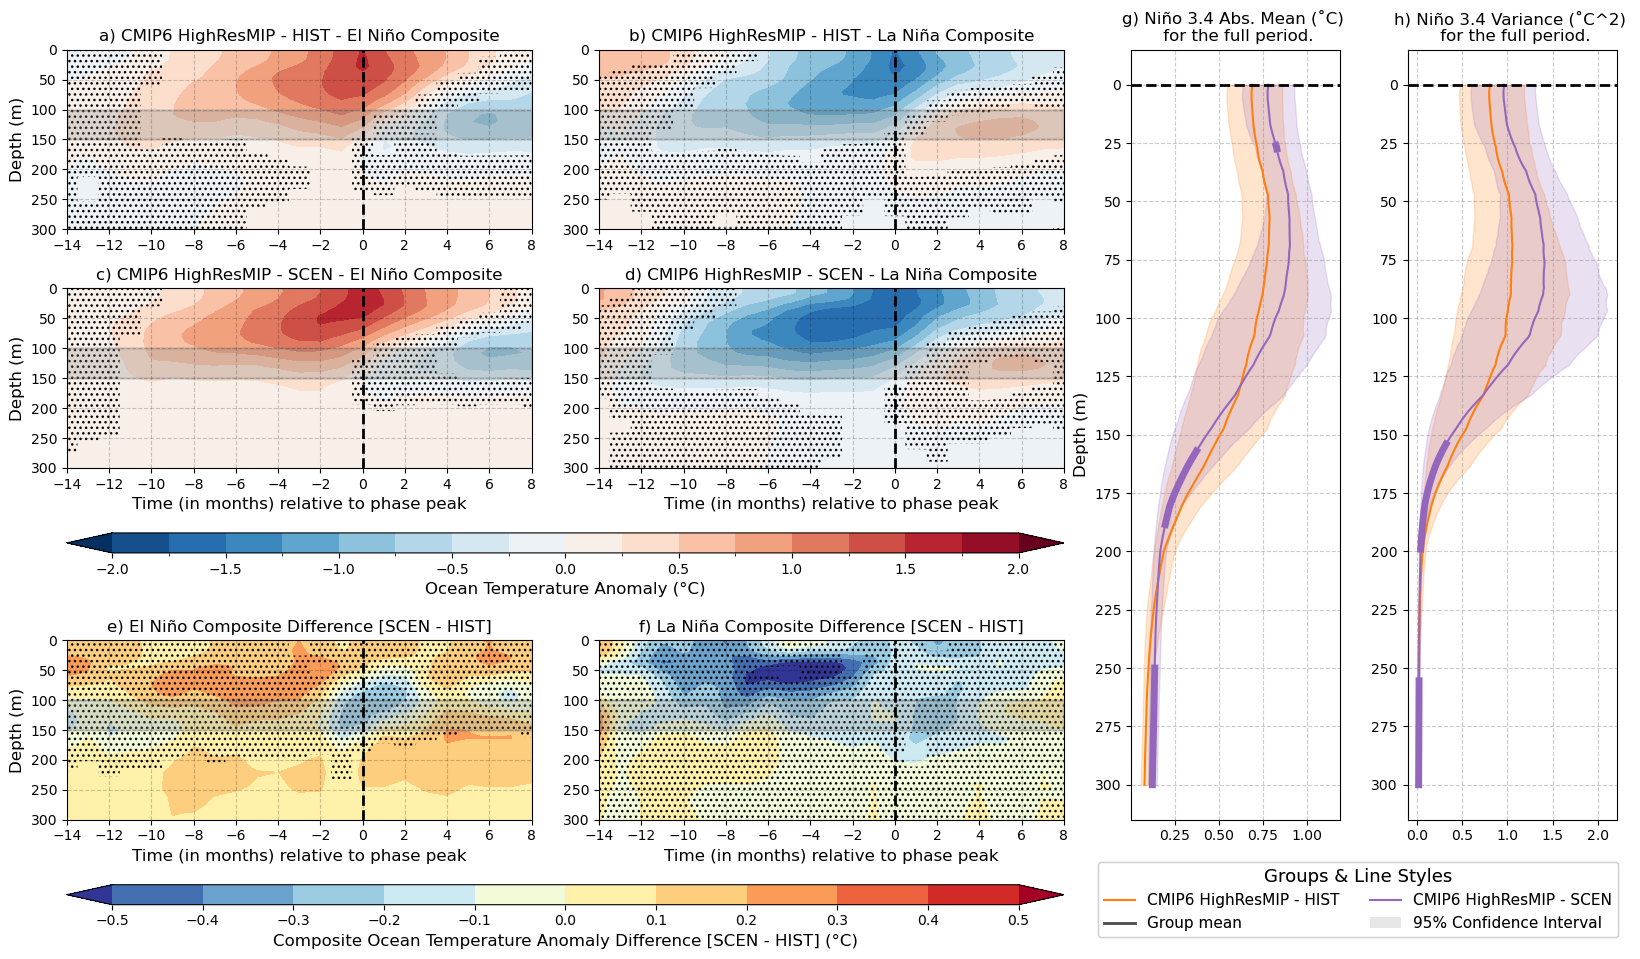

In [52]:
# =============================================================================
# CONFIGURING THE FIGURE AND GRID SPECIFICATIONS
# =============================================================================
fig = plt.figure(figsize=(20, 10))

# 4 rows, 4 columns:
#   rows 0-1, columns 0-1: 2x2 event-centred group-mean composites (rows: HIST, SCEN; columns: El Niño, La Niña)
#   row 2: spacer (small height)
#   row 3, columns 0-1: 1x2 SCEN - HIST difference composites
#   columns 2-3: Niño 3.4 mean and variance profiles (one tall panel each, spanning all rows)
gs = fig.add_gridspec(nrows=4, ncols=4,  height_ratios=[1.0, 1.0, 0.3, 1.0],
                      width_ratios=[1.0, 1.0, 0.45, 0.45], wspace=0.20, hspace=0.4,)

# Left block (2 cols, 2 rows)
ax_event_comp = np.empty((2, 2), dtype=object)
for r in range(2):
    for c in range(2):
        ax_event_comp[r, c] = fig.add_subplot(gs[r, c])

ax_bias_en = fig.add_subplot(gs[3, 0])
ax_bias_ln = fig.add_subplot(gs[3, 1])

# Right block (two vertical panels spanning all rows)
ax_n34_mean_prof = fig.add_subplot(gs[:, 2])
ax_n34_var_prof = fig.add_subplot(gs[:, 3], sharey=ax_n34_mean_prof)

# =============================================================================
# PLOTTING THE LEFT BLOCK: GROUP-MEAN EVENT-CENTRED HOVMÖLLER COMPOSITES
# =============================================================================
title_encoding = {'HIST': 'CMIP6 HighResMIP - HIST', 'SCEN_F': 'CMIP6 HighResMIP - SCEN',}
                  
for idx, _ in enumerate(['HIST', 'SCEN_F']):
    # Composites ('M': group mean, 'sig': cross-dataset significance agreement mask) of this group, per ENSO phase
    ds_en = ENSO_N34_HOV_EVENT_COMPOSITE.sel(comp = _, phase = 'EL-NINO')
    ds_ln = ENSO_N34_HOV_EVENT_COMPOSITE.sel(comp = _, phase = 'LA-NINA')

    # El Niño event-centred composites + cross-dataset significance agreement mask
    ds_en['M'].transpose().plot.contourf(yincrease=False, ax=ax_event_comp[idx, 0],
                                         levels=np.arange(-2, 2.1, 0.25), add_colorbar=False, extend='both')
    c_hatch1 = ax_event_comp[idx, 0].contourf(ds_en.time, ds_en.depth, ds_en['sig'].transpose(),
                                              levels = [-0.5, 0.5], hatches = ['...'], colors="none")
    c_hatch1._hatch_color = color_shade

    # La Niña event-centred composites + cross-dataset significance agreement mask
    cbar_left_block = ds_ln['M'].transpose().plot.contourf(yincrease=False, ax=ax_event_comp[idx, 1],
                                                           levels=np.arange(-2, 2.1, 0.25), add_colorbar=False,
                                                           extend='both')
    c_hatch2 = ax_event_comp[idx, 1].contourf(ds_ln.time, ds_ln.depth, ds_ln['sig'].transpose(),
                                              levels = [-0.5, 0.5], hatches = ['...'], colors="none")
    c_hatch2._hatch_color = color_shade

    ax_event_comp[idx, 0].set_title(f'{chr(ord('a') + 2*idx)}) {title_encoding[_]} - El Niño Composite', fontsize=12)
    ax_event_comp[idx, 1].set_title(f'{chr(ord('a') + 2*idx + 1)}) {title_encoding[_]} - La Niña Composite', fontsize=12)

# =============================================================================
# PLOTTING THE LEFT BLOCK: SCEN - HIST DIFFERENCES OF THE EVENT-CENTRED HOVMÖLLER COMPOSITES
# =============================================================================

# SCEN_F - HIST difference composites ('D') and significance masks ('sig') of each ENSO phase
ds_diff_en = ENSO_N34_HOV_EVENT_COMPOSITE.sel(comp = 'SCEN_F-HIST', phase = 'EL-NINO')
ds_diff_ln = ENSO_N34_HOV_EVENT_COMPOSITE.sel(comp = 'SCEN_F-HIST', phase = 'LA-NINA')

# El Niño difference composites + significance mask
ds_diff_en['D'].transpose().plot.contourf(yincrease=False, ax=ax_bias_en,
                                          levels=np.arange(-0.5, 0.51, 0.1), add_colorbar=False, extend='both', cmap = 'RdYlBu_r')
c_hatch1 = ax_bias_en.contourf(ds_diff_en.time, ds_diff_en.depth, ds_diff_en['sig'].transpose(),
                               levels = [-0.5, 0.5], hatches = ['...'], colors="none")
c_hatch1._hatch_color = color_shade

# La Niña difference composites + significance mask
cbar_left_block_bias = ds_diff_ln['D'].transpose().plot.contourf(yincrease=False, ax=ax_bias_ln,
                                                                 levels=np.arange(-0.5, 0.51, 0.1), add_colorbar=False,
                                                                 extend='both', cmap = 'RdYlBu_r')
c_hatch2 = ax_bias_ln.contourf(ds_diff_ln.time, ds_diff_ln.depth, ds_diff_ln['sig'].transpose(),
                               levels = [-0.5, 0.5], hatches = ['...'], colors="none")
c_hatch2._hatch_color = color_shade

ax_bias_en.set_title('e) El Niño Composite Difference [SCEN - HIST]', fontsize=12)
ax_bias_ln.set_title('f) La Niña Composite Difference [SCEN - HIST]', fontsize=12)

# =============================================================================
# PLOTTING THE RIGHT BLOCK: GROUP-MEAN MEAN AND VARIANCE NIÑO 3.4 PROFILES
# =============================================================================

# Plotting group-mean Niño 3.4 mean and variance profiles for the full time series, with the 95% CI of the bootstrap (shading)
for c, group in zip(['C1', 'C4'], ['HighResMIP-HIST', 'HighResMIP-SCEN']):
    ci_lo = group_n34_stats[['mean_boot', 'var_boot']].sel(group = group).quantile(q=0.025, dim='boot')
    ci_hi = group_n34_stats[['mean_boot', 'var_boot']].sel(group = group).quantile(q=0.975, dim='boot')
    sig = group_n34_stats[['pval_mean', 'pval_var']] < 0.05
    ax_n34_mean_prof.plot(group_n34_stats['mean'].sel(group = group),group_n34_stats['depth'], color = c, label = title_encoding['HIST' if 'HIST' in group else 'SCEN_F'], lw = 1.5)
    ax_n34_mean_prof.fill_betweenx(y = group_n34_stats['mean'].depth, x1 = ci_lo['mean_boot'], x2 = ci_hi['mean_boot'], color = c, alpha = 0.2)
    ax_n34_var_prof.plot(group_n34_stats['var'].sel(group = group), group_n34_stats['depth'], color = c, label = title_encoding['HIST' if 'HIST' in group else 'SCEN_F'], lw = 1.5)
    ax_n34_var_prof.fill_betweenx(y = group_n34_stats['var'].depth, x1 = ci_lo['var_boot'], x2 = ci_hi['var_boot'], color = c, alpha = 0.2)    

    # Thick line where SCEN differs significantly from HIST (p < 0.05)
    if group == 'HighResMIP-SCEN':
        ax_n34_mean_prof.plot(group_n34_stats['mean'].sel(group = group).where(sig['pval_mean']),group_n34_stats['depth'], color = c, lw = 5)
        ax_n34_var_prof.plot(group_n34_stats['var'].sel(group = group).where(sig['pval_var']),group_n34_stats['depth'], color = c, lw = 5)

ax_n34_mean_prof.invert_yaxis()
ax_n34_var_prof.invert_yaxis()
ax_n34_mean_prof.set_title('g) Niño 3.4 Abs. Mean (˚C) \n for the full period.')
ax_n34_var_prof.set_title('h) Niño 3.4 Variance (˚C^2) \n for the full period.')

# =============================================================================
# AXES STYLING AND GUIDE LINES
# =============================================================================
#  Formatting for left block
for i, ax in enumerate(flatten(ax_event_comp) + [ax_bias_en, ax_bias_ln]):
    format_axis(ax, kind = 'event_comp', i = i, last_row = False)
    ax.set_xlim([-14,8])
    ax.set_ylim([300,0])

for _ in list(ax_event_comp[1,:])+[ax_bias_en, ax_bias_ln]:
    last_row = True
    _.set_xlabel('Time (in months) relative to phase peak' if last_row == True else '', fontsize=12,)

#  Formatting for right block
for ax in [ax_n34_mean_prof, ax_n34_var_prof]:
    ax.set_yticks(np.arange(0, 300.1, 25))
    ax.grid(True, color='gray', ls='--', alpha=0.4)
    ax.axhline(0, ls='--', color='k', lw=2)
    ax.set_xlabel('')
ax.invert_yaxis()
# Show y-label only on the left of the right block
ax_n34_mean_prof.set_ylabel('Depth (m)', fontsize = 12)

# =============================================================================
# LEGEND ITEMS FOR RIGHT BLOCK SUBPLOTS
# =============================================================================
# Gather coloured-line handles without duplicates (from both right axes)
handles_all, labels_all = [], []
for ax in [ax_n34_mean_prof, ax_n34_var_prof]:
    h, l = ax.get_legend_handles_labels()
    for hh, ll in zip(h, l):
        if ll not in labels_all:
            handles_all.append(hh)
            labels_all.append(ll)

# Add the style handles to the same list
mean_handle   = Line2D([0], [0], color='0.3', lw=2, label='Group mean')
spread_handle = Patch(facecolor='0.6', edgecolor='none', alpha=0.2, label='95% Confidence Interval')
handles_all += [mean_handle, spread_handle]
labels_all += ['Group mean', '95% Confidence Interval']

# Reorder (the legend fills column by column): left column = HIST, Group mean
#                                              right column = SCEN, 95% Confidence Interval
# Original handles_all order: [HIST, SCEN]
ordered_handles = [handles_all[0], mean_handle,
                   handles_all[1], spread_handle]
ordered_labels  = [labels_all[0], 'Group mean',
                   labels_all[1], '95% Confidence Interval']

leg_combined = fig.legend(ordered_handles, ordered_labels, loc='lower right', title = 'Groups & Line Styles',
                                       ncols=2, frameon=True, fontsize=11, title_fontsize = 13, bbox_to_anchor=(0.9044, -0.015))
fig.add_artist(leg_combined)

# =============================================================================
# SHARED COLORBAR FOR LEFT BLOCK SUBPLOTS
# =============================================================================
add_colorbar(fig, axes = list(ax_event_comp.flatten()), mappable = cbar_left_block,
             label = 'Ocean Temperature Anomaly (°C)', ticks=np.arange(-2, 2.1, 0.5), 
             side = 'bottom',  height=0.020, pad = 0.085, labelsize = 12, ticksize = 10)

add_colorbar(fig, axes = [ax_bias_en, ax_bias_ln], mappable = cbar_left_block_bias,
             label = 'Composite Ocean Temperature Anomaly Difference [SCEN - HIST] (°C)', 
             ticks=np.arange(-0.5, 0.51, 0.1), side = 'bottom',  height=0.020, pad = 0.085, 
             labelsize = 12, ticksize = 10)

# Tight layout after legends and colourbar
fig.tight_layout(rect=(0.04, 0.09, 0.98, 0.98))
fig.savefig(f'{FIG_DIR}figure_10.png', bbox_inches = 'tight', dpi = 300)

### Figure 11: Vertical profile of temp extremes characterizing ENSO (from composites)

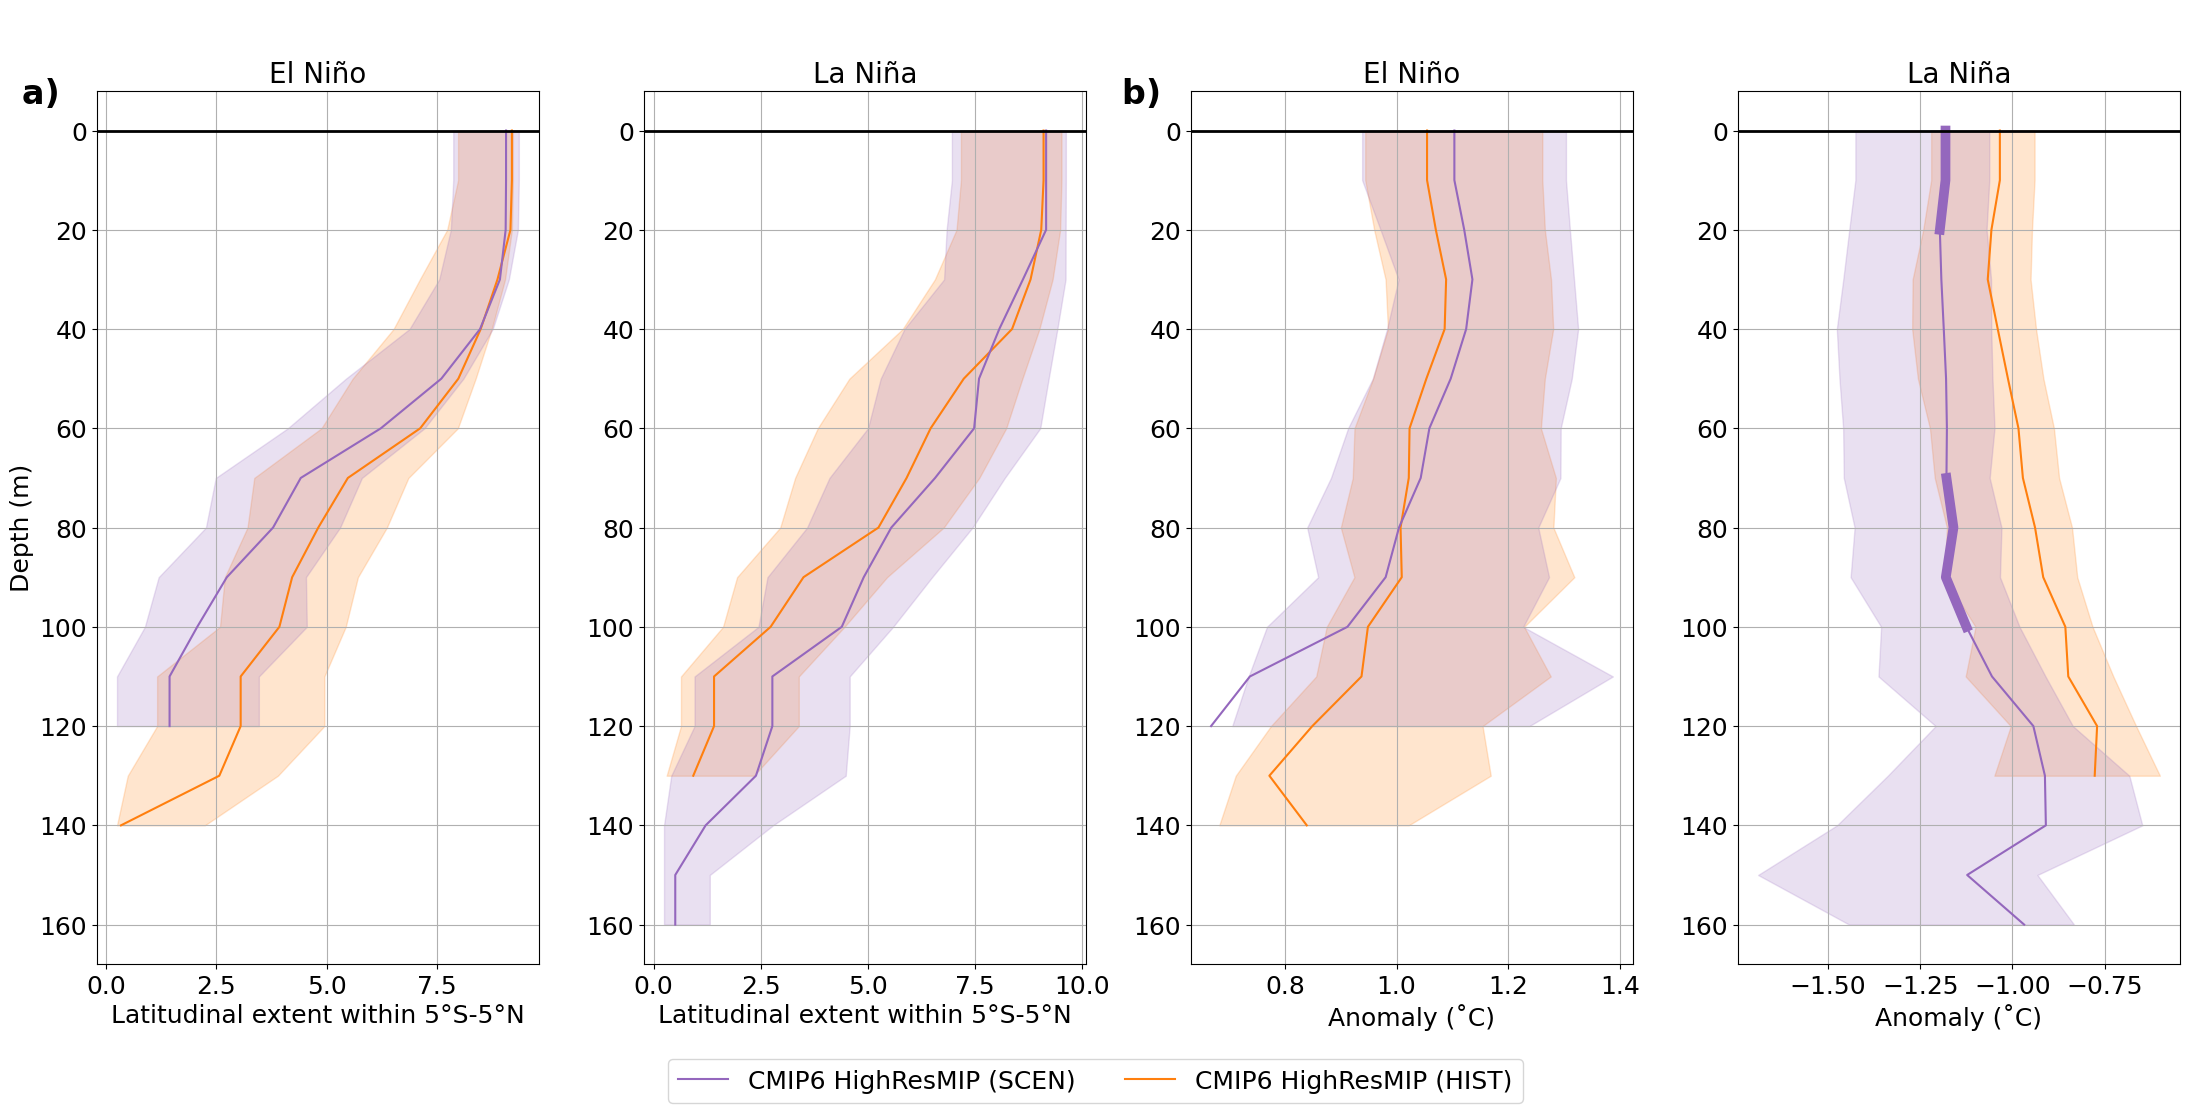

In [ ]:
# Reading in the bootstrapped datasets (written by appendices/appendix_A.ipynb) for the masked temperature extremes (EXTENT and
# INTENSITY) of each group and ENSO phase: the group mean (BOOTSTRAP_DIR) and, for SCEN, its difference to HIST (BOOTSTRAP_DIR_BIAS).
# The SCEN files are labelled SCEN_F (full 2015-2050 scenario) and SCEN_T (truncated 2015-2040 scenario) on disk

# =============================================================================
# PLOTTING VERTICAL PROFILE OF MASKED TEMPERATURE EXTREMES
# =============================================================================
fig, ax = plt.subplots(1,4, figsize = (22,10), sharey = True)
label_encoding = {'HIST': 'CMIP6 HighResMIP (HIST)', 'SCEN': 'CMIP6 HighResMIP (SCEN)'}    

for group, file_label, C in zip(['HIST', 'SCEN'], ['HIST', 'SCEN_F'], ['C1', 'C4']):
    # One dataset per ENSO phase: columns of ax are (EXTENT: EN, LN | INTENSITY: EN, LN)
    ext_prof = {phase: xr.open_dataset(glob.glob(BOOTSTRAP_DIR.format(label=file_label, phase=phase))[0]) for phase in ['EL-NINO', 'LA-NINA']}
    if group != 'HIST': # HIST is the reference of the differences, so it has no bias dataset
        ext_prof_bias = {phase: xr.open_dataset(glob.glob(BOOTSTRAP_DIR_BIAS.format(label=file_label, phase=phase))[0]) for phase in ['EL-NINO', 'LA-NINA']}
    for m, metric in enumerate(['EXTENT', 'INTENSITY']):
        for p, phase in enumerate(['EL-NINO', 'LA-NINA']):
            ds, a = ext_prof[phase], ax[2*m + p]
            M = ds['M'].sel(type=metric)
            a.plot(M.values, ds.depth.values, color=C, ls='-', label=label_encoding[group])

            if group != 'HIST':
                sig = ext_prof_bias[phase]['sig'].sel(type=metric)
                a.plot(M.where(sig).values, ds.depth.values, color=C, ls='-', lw=7) # Thick line where the difference to HIST is significant
            # Fill between the 95% confidence intervals for each group and phase
            a.fill_betweenx(ds.depth.values, ds['lo'].sel(type=metric).values, ds['hi'].sel(type=metric).values, color=C, alpha=0.2)

for i, _ in enumerate(ax):
    format_axis(ax=_, kind='vert_prof', i=i)
    _.tick_params(labelleft=True)
ax[0].invert_yaxis()
ax[0].set_title('El Niño', fontsize = 20)
ax[2].set_title('El Niño', fontsize = 20)
ax[1].set_title('La Niña', fontsize = 20)
ax[3].set_title('La Niña', fontsize = 20)
ax[1].set_ylabel('')
ax[2].set_ylabel('')
ax[3].set_ylabel('')
# =============================================================================
# LEGEND ITEMS
# =============================================================================
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes]
lines, labels = [sum(x, []) for x in zip(*lines_labels)]
# Grabbing unique labels (a set, so the legend order can vary between runs)
unique_labels = set(labels)
# Assigning labels and legends in dict
legend_dict = dict(zip(labels, lines))
# Query dict based on unique labels
unique_lines = [legend_dict[x] for x in unique_labels]
fig.legend(unique_lines, unique_labels, ncols = 5, loc = 'lower center', bbox_to_anchor=(0.5, -0.07), fontsize=18)

fig.tight_layout(w_pad = 2.5)

# Panel letters: a) EXTENT, b) INTENSITY
plt.annotate('a) ', xy = (0.01, 1.01), fontsize = 24, fontweight = 'bold', xycoords='figure fraction')
plt.annotate('b) ', xy = (0.51, 1.01), fontsize = 24, fontweight = 'bold', xycoords='figure fraction')
fig.savefig(f'{FIG_DIR}figure_11.png', bbox_inches = 'tight', dpi = 300)

## Section 4: Discussion

### Figure 12: Group-mean thermocline (i.e., depth of 20˚C isotherm; Z20) climatological depth and depth bias during ENSO.

In [ ]:
# =============================================================================
# READING IN THE Z20 DEPTH FILES AND CONCATENATING BY DATASET
# =============================================================================
# Z20 time series (variable 'z20', written by data_prep.ipynb) of each period and the datasets it contains:
# HIST: HIST runs plus NPD and OBS (1979-2014); SCEN: SCEN runs only (2015-2050)
Z20_PERIODS = {'HIST': (HIGHRESMIP_EXPS_HIST + NPD_EXPS + OBS, ('1979', '2014')),
               'SCEN': (HIGHRESMIP_EXPS_SCEN, ('2015', '2050'))}

Z20_DEPTHS = {'HIST': [], 'SCEN': []}
for period, (datasets, years) in Z20_PERIODS.items():
    for dataset in tqdm(datasets):
        ds_z20 = xr.open_dataset(glob.glob(f'{Z20_DIR}Z20_DEPTHS_{dataset}_????-????.nc')[0])['z20']
        Z20_DEPTHS[period] += [ds_z20.sel(time = slice(*years)).assign_coords(dataset = [dataset])]
        del ds_z20

Z20_DEPTHS['HIST'] = xr.concat(Z20_DEPTHS['HIST'], dim = 'dataset').compute()
Z20_DEPTHS['SCEN'] = xr.concat(Z20_DEPTHS['SCEN'], dim = 'dataset').compute()

# =============================================================================
# LOADING IN ENSO EVENT TIMESTAMPS TO COMPUTE ENSO COMPOSITE Z20 DEPTH
# =============================================================================
# Timestamps written by enso_preprocessing.py: {dataset: {'EL-NINO': [months of each event, ...], 'LA-NINA': [...]}}
ENSO_EVENT_TS = {}
with open(f"{DATA_DIR}ENSO_EVENT_TIMESTAMPS_{PERIOD_LABELS['HIST']}.pkl", 'rb') as f:
    ENSO_EVENT_TS['HIST'] = pickle.load(f)

with open(f"{DATA_DIR}ENSO_EVENT_TIMESTAMPS_{PERIOD_LABELS['SCEN_F']}.pkl", 'rb') as f:
    ENSO_EVENT_TS['SCEN'] = pickle.load(f)

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

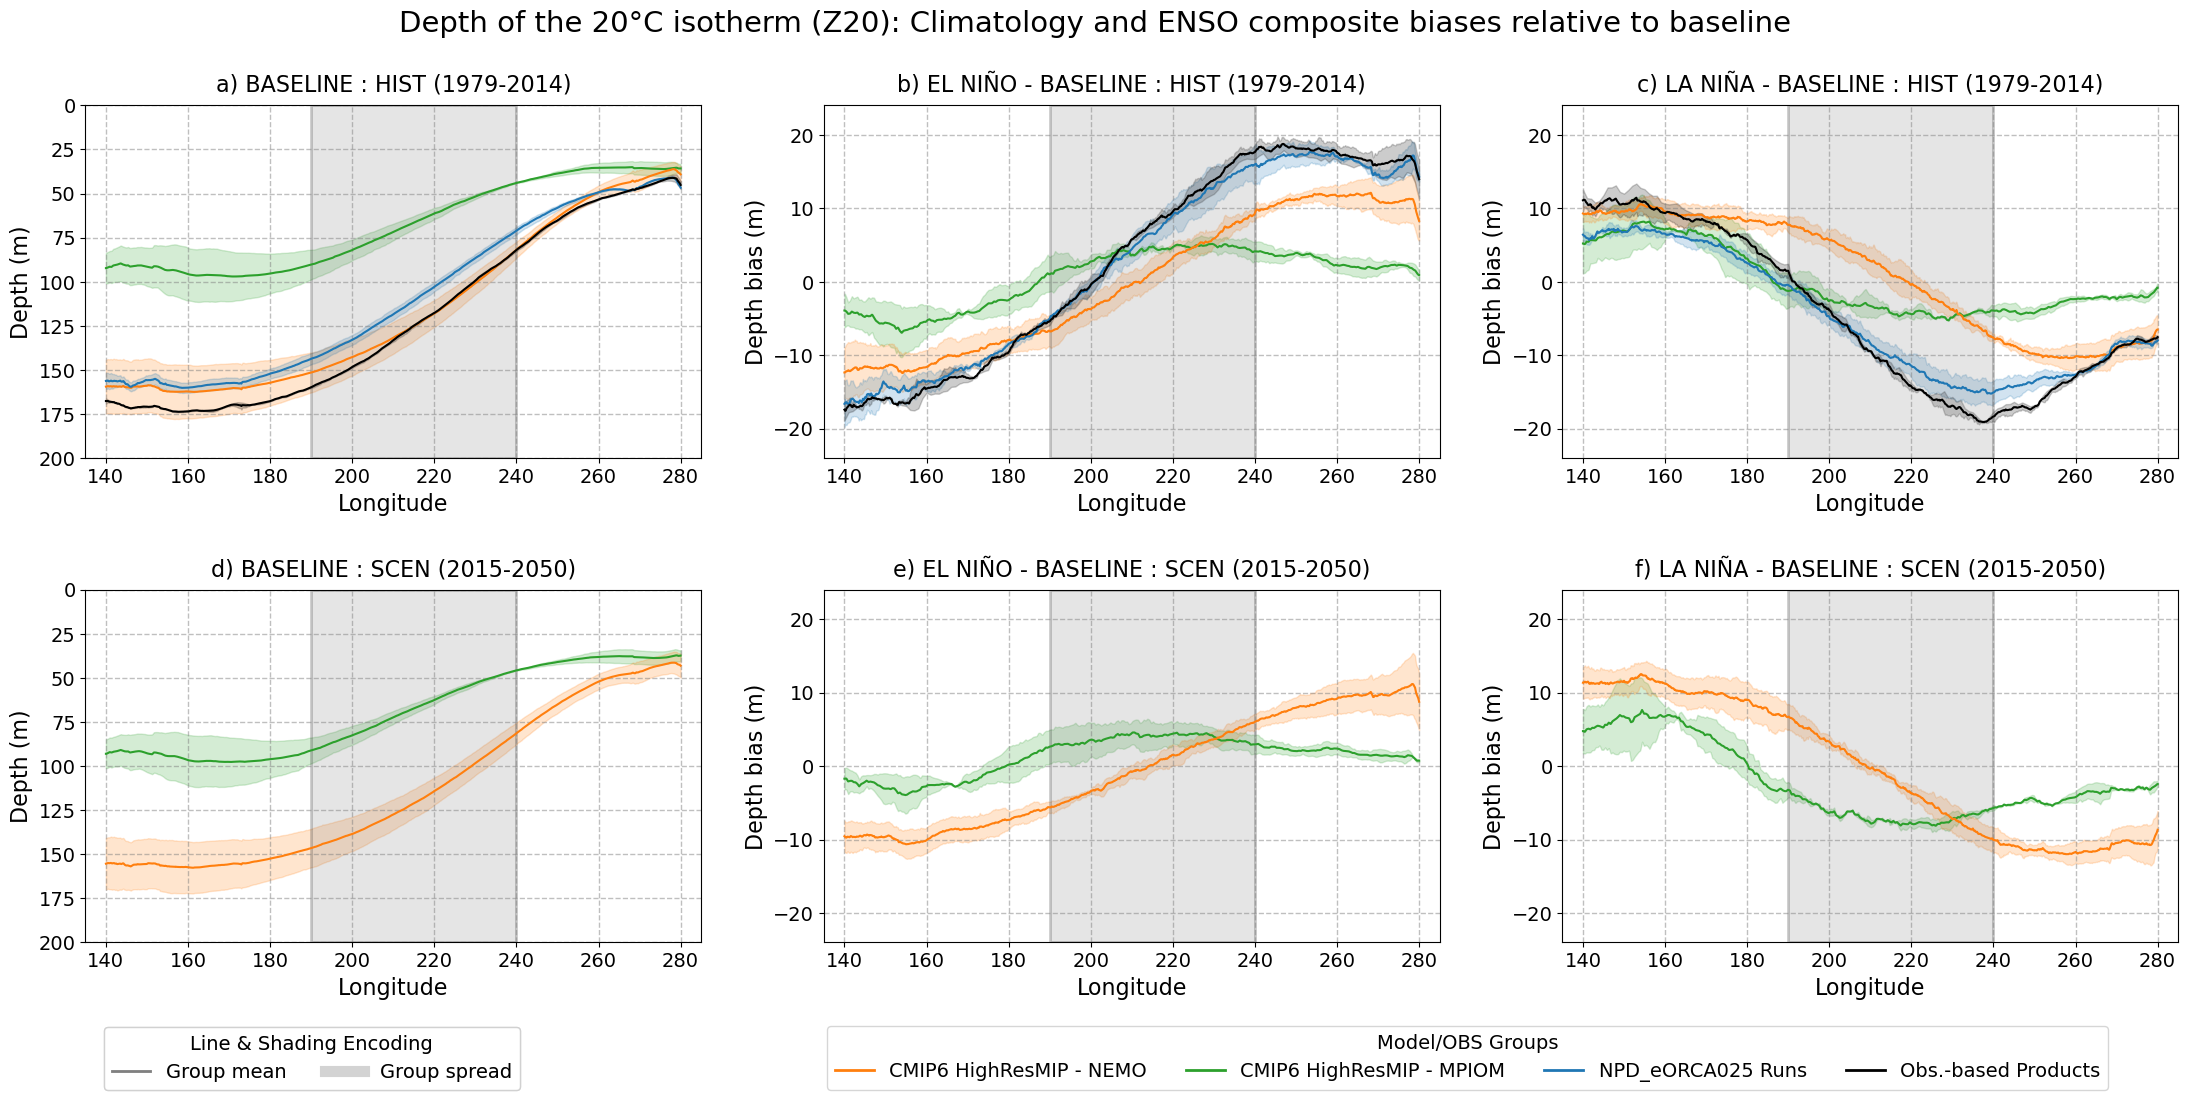

In [12]:
# =============================================================================
# PLOTTING CLIMATOLOGICAL MEAN Z20 DEPTH AND Z20 BIAS DURING ENSO
# =============================================================================
fig, ax = plt.subplots(2,3, figsize = (22,10))
fig.suptitle('Depth of the 20°C isotherm (Z20): Climatology and ENSO composite biases relative to baseline', fontsize = 21, y = 1.005)
for period, ax_list in zip(['HIST', 'SCEN'], ax):
    dataset_list = HIGHRESMIP_EXPS_HIST if period == 'HIST' else HIGHRESMIP_EXPS_SCEN
    # Plotting Z20 depths and biases of HighResMIP-MPIOM models (the MPI-ESM1-2 models; all other models use NEMO)
    z20_grp_calc(da_z20 = Z20_DEPTHS[period].sel(dataset = [_ for _ in (dataset_list) if 'MPI' in _]), 
                 enso_timestamps = ENSO_EVENT_TS[period], axes = ax_list,  
                 color  = 'C2', label = 'CMIP6 HighResMIP - MPIOM')
    # Plotting Z20 depths and biases of HighResMIP-NEMO models
    z20_grp_calc(da_z20 = Z20_DEPTHS[period].sel(dataset = [_ for _ in (dataset_list) if 'MPI' not in _]),  
                 enso_timestamps = ENSO_EVENT_TS[period], axes = ax_list,  
                 color  = 'C1', label = 'CMIP6 HighResMIP - NEMO')
    
    if period == 'HIST':
        # Plotting Z20 depths and biases of NPD_eORCA025 runs
        z20_grp_calc(da_z20 = Z20_DEPTHS[period].sel(dataset = NPD_EXPS),  
                     enso_timestamps = ENSO_EVENT_TS[period], axes = ax_list,  
                     color  = 'C0', label = 'NPD_eORCA025 Runs')
        # Plotting Z20 depths and biases of observational data
        z20_grp_calc(da_z20 = Z20_DEPTHS[period].sel(dataset = OBS),  
                     enso_timestamps = ENSO_EVENT_TS[period], axes = ax_list,  
                     color  = 'k', label = 'Obs.-based Products')
    # Formatting the axes
    for i, _ in enumerate(ax_list):
        format_axis(ax = _, kind = 'z20', i = i)

# Setting title for each sub-panel plot
ax[0,0].set_title('a) BASELINE : HIST (1979-2014)', fontsize = 16, pad = 10)
ax[0,1].set_title('b) EL NIÑO - BASELINE : HIST (1979-2014)', fontsize = 16, pad = 10)
ax[0,2].set_title('c) LA NIÑA - BASELINE : HIST (1979-2014)', fontsize = 16, pad = 10)
ax[1,0].set_title('d) BASELINE : SCEN (2015-2050)', fontsize = 16, pad = 10)
ax[1,1].set_title('e) EL NIÑO - BASELINE : SCEN (2015-2050)', fontsize = 16, pad = 10)
ax[1,2].set_title('f) LA NIÑA - BASELINE : SCEN (2015-2050)', fontsize = 16, pad = 10)

# =============================================================================
# LEGEND ITEMS
# =============================================================================

# Left block: Line & Shading Encoding
style_handles = [Line2D([0], [0], color='grey', linewidth=2, linestyle='-', label='Group mean'),
                 Line2D([0], [0], color='grey', linewidth=8, alpha=0.3, label='Group spread')]

# Right block: Datasets/Groups
group_handles = [Line2D([0], [0], color='C1', linewidth=2, label='CMIP6 HighResMIP - NEMO'),
                 Line2D([0], [0], color='C2', linewidth=2, label='CMIP6 HighResMIP - MPIOM'),
                 Line2D([0], [0], color='C0', linewidth=2, label='NPD_eORCA025 Runs'),
                 Line2D([0], [0], color='k',  linewidth=2, label='Obs.-based Products')]

leg1 = fig.legend(handles=style_handles, loc='lower left', bbox_to_anchor=(0.045, -0.085), ncol=2, frameon=True, 
                  title='Line & Shading Encoding', title_fontproperties={'size': 14}, prop={'size': 14})
fig.legend(handles=group_handles, loc='lower right', bbox_to_anchor=(0.965, -0.085), ncol=4, frameon=True, 
                  title='Model/OBS Groups', title_fontproperties={'size': 14}, prop={'size': 14})
fig.add_artist(leg1)

fig.tight_layout(h_pad=3, w_pad=3)
fig.savefig(f'{FIG_DIR}figure_12.png', bbox_inches = 'tight', dpi = 300)

### Figure 13: Zonal wind anomaly composites during ENSO events.

In [ ]:
# Dictionary to save zonal wind anomaly composites for El Niño and La Niña months
ZON_WND_ANOM_COMPOSITE = {'EL-NINO' : {'HIST' : [], 'SCEN' : []},
                          'LA-NINA' : {'HIST' : [], 'SCEN' : []}}

# Composites of the HIST runs (sampled at the HIST-period ENSO event months) and of the SCEN runs (SCEN-period event months)
for period, datasets in [('HIST', HIGHRESMIP_EXPS_HIST), ('SCEN', HIGHRESMIP_EXPS_SCEN)]:
    for dataset in tqdm(datasets):
        ds_zon_wnd_anom = xr.open_dataset(f'{WND_DIR}BILINTERP_PAC_ZON_WND_ANOM_850HPA_{dataset}.nc')
        # The model time stamps are mid-month (16th): set them to the 1st to match the event timestamps
        ds_zon_wnd_anom['time'] = pd.to_datetime([str(_)[:8]+'01' for _ in ds_zon_wnd_anom['time'].values])
        for event_type in ZON_WND_ANOM_COMPOSITE.keys():
            ZON_WND_ANOM_COMPOSITE[event_type][period] += [ds_zon_wnd_anom['ua_anom'].sel(time = flatten(ENSO_EVENT_TS[period][dataset][event_type])).mean(dim = ['time'])]

# Concatenating composites across the 'dataset' dimension
for event_type in ZON_WND_ANOM_COMPOSITE.keys():
    ZON_WND_ANOM_COMPOSITE[event_type]['HIST'] = xr.concat(ZON_WND_ANOM_COMPOSITE[event_type]['HIST'], dim = 'dataset')
    ZON_WND_ANOM_COMPOSITE[event_type]['SCEN'] = xr.concat(ZON_WND_ANOM_COMPOSITE[event_type]['SCEN'], dim = 'dataset')

# Zonal wind anomalies (variable 'ua', 1976-2023) from the ERA5 reanalysis, as observational benchmark. They are sampled at the
# 1979-2014 event months of NPD_eORCA025_ERA5 (the ERA5-forced ocean run)
ZON_WND_ANOM_COMPOSITE_ERA5 = {}

ds_zon_wnd_anom_era5 = xr.open_dataset(f'{WND_DIR}BILINTERP_PAC_UV_WND_ANOM_850HPA_ERA5_REANALYSIS_1976-2023.nc').sel(time = slice('1979', '2014'))
ZON_WND_ANOM_COMPOSITE_ERA5['EL-NINO'] = ds_zon_wnd_anom_era5['ua'].sel(time = flatten(ENSO_EVENT_TS['HIST']['NPD_eORCA025_ERA5']['EL-NINO'])).mean(dim = ['time'])
ZON_WND_ANOM_COMPOSITE_ERA5['LA-NINA'] = ds_zon_wnd_anom_era5['ua'].sel(time = flatten(ENSO_EVENT_TS['HIST']['NPD_eORCA025_ERA5']['LA-NINA'])).mean(dim = ['time'])

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

/tmp/ipykernel_3929468/4007713303.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


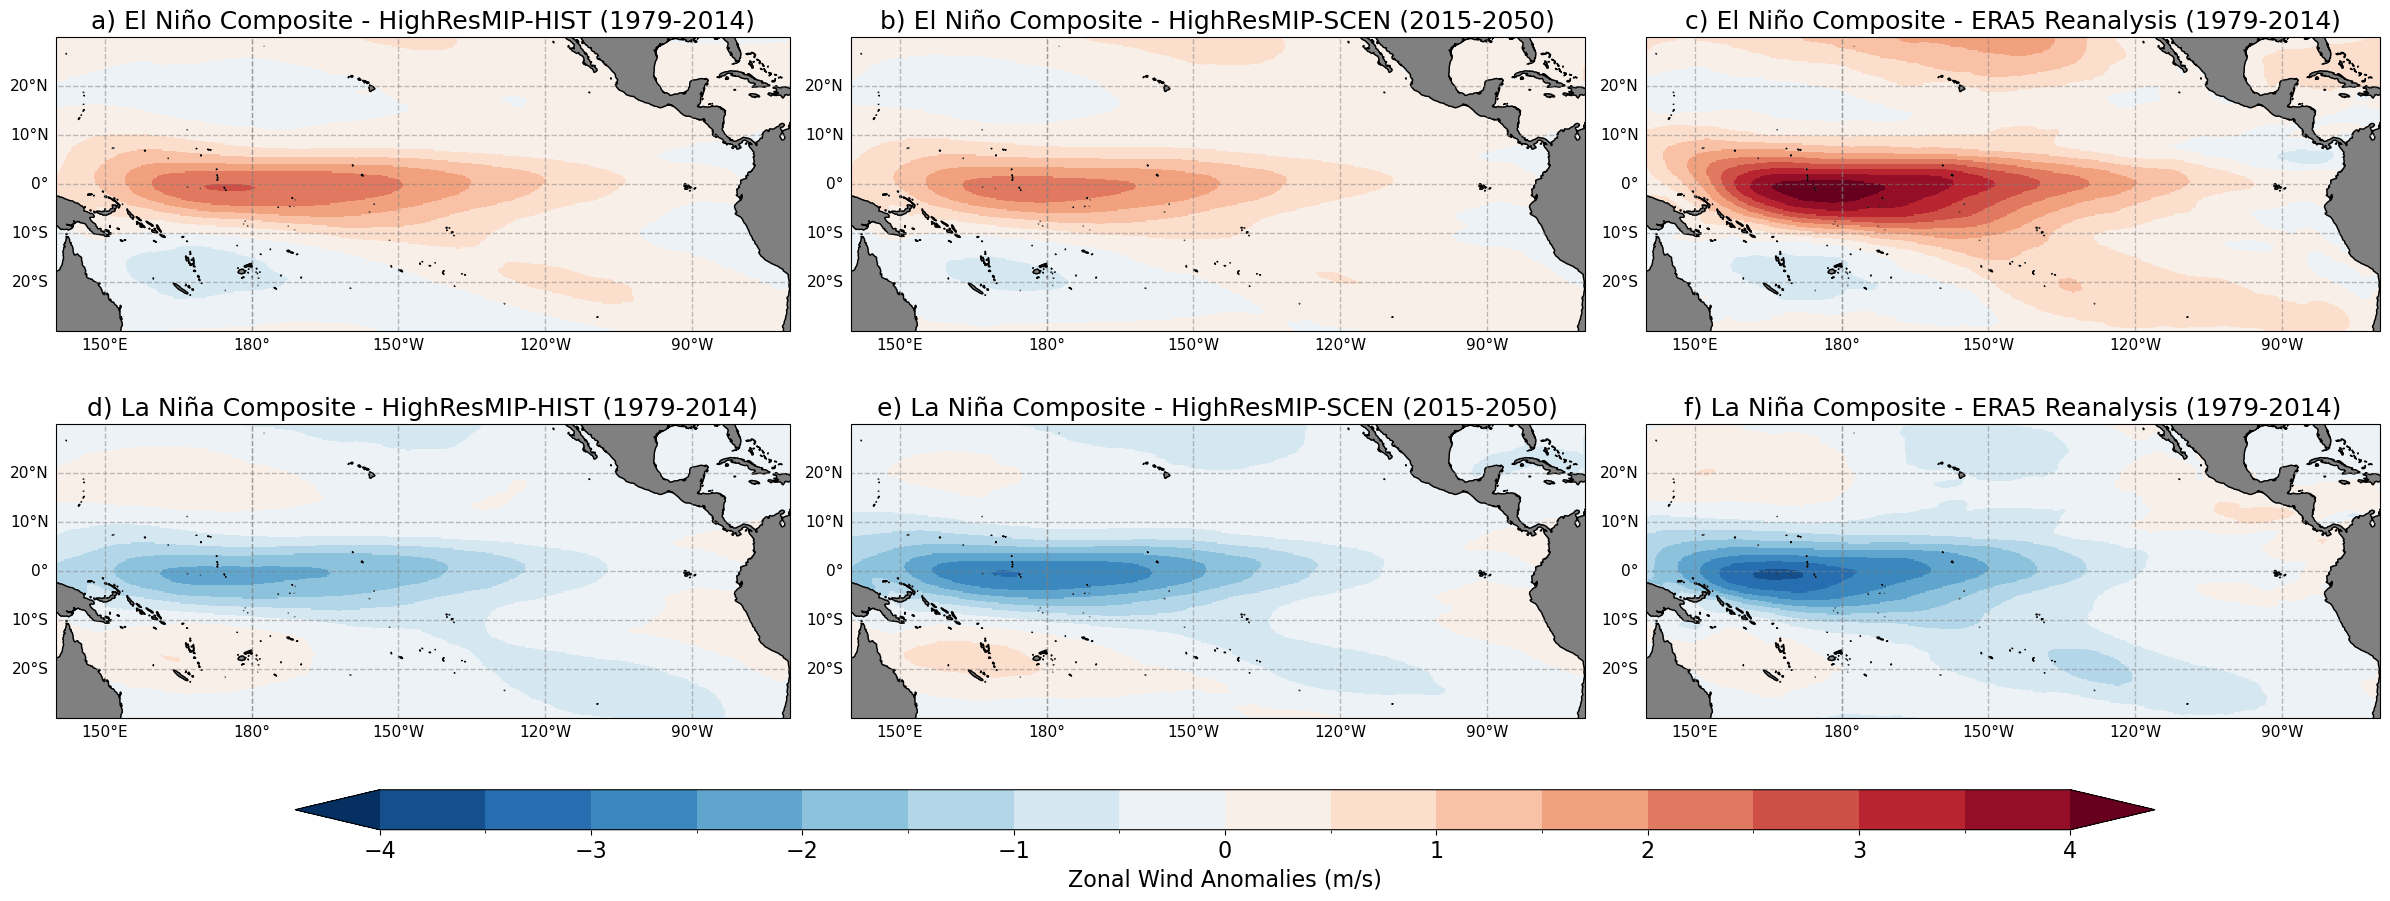

In [9]:
# =============================================================================
# PLOTTING ZONAL WIND ANOMALY COMPOSITES - CMIP6 HIGHRESMIP VS. ERA5
# =============================================================================
fig, ax = plt.subplots(2,3, figsize = (24,8), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for event_type, ax_list in zip(ZON_WND_ANOM_COMPOSITE.keys(), ax):
    # Plotting the ENSO zonal wind anomaly composite for the HighResMIP - Historical period
    ZON_WND_ANOM_COMPOSITE[event_type]['HIST'].mean(dim = ['dataset']).plot(x = 'lon', y = 'lat', ax = ax_list[0], add_colorbar = False, transform=ccrs.PlateCarree(),
                                                                           levels = np.arange(-4,4.1,0.5), extend = 'both')
    # Plotting the ENSO zonal wind anomaly composite for the HighResMIP - Scenario period
    ZON_WND_ANOM_COMPOSITE[event_type]['SCEN'].mean(dim = ['dataset']).plot(x = 'lon', y = 'lat', ax = ax_list[1], add_colorbar = False, transform=ccrs.PlateCarree(),
                                                                           levels = np.arange(-4,4.1,0.5), extend = 'both')
    # Plotting the ENSO zonal wind anomaly composite for the ERA5 reanalysis data
    cbar = ZON_WND_ANOM_COMPOSITE_ERA5[event_type].plot(x = 'lon', y = 'lat', ax = ax_list[2], add_colorbar = False, transform=ccrs.PlateCarree(),
                                                        levels = np.arange(-4,4.1,0.5), extend = 'both')
    # Formatting the axes
    for _ in ax_list:
        format_axis(ax = _, kind = 'map', land_ft = land_50m, coast_ft = coast_50m)
        
# Setting title for each sub-panel plot
ax[0,0].set_title('a) El Niño Composite - HighResMIP-HIST (1979-2014)', size = 18)
ax[0,1].set_title('b) El Niño Composite - HighResMIP-SCEN (2015-2050)', size = 18)
ax[0,2].set_title('c) El Niño Composite - ERA5 Reanalysis (1979-2014)', size = 18)
ax[1,0].set_title('d) La Niña Composite - HighResMIP-HIST (1979-2014)', size = 18)
ax[1,1].set_title('e) La Niña Composite - HighResMIP-SCEN (2015-2050)', size = 18)
ax[1,2].set_title('f) La Niña Composite - ERA5 Reanalysis (1979-2014)', size = 18)

# Adding a shared colourbar at the bottom of the figure (mappable of the last ERA5 panel; all panels share the levels)
add_colorbar(fig, axes = ax.flatten(), mappable = cbar, label = 'Zonal Wind Anomalies (m/s)', 
             ticks=np.arange(-4,4.1,1), side = 'bottom', height=0.05, pad = 0.175, 
             labelsize = 16, ticksize = 16)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}figure_13.png', bbox_inches='tight', dpi=300)

In [ ]:
# Shut down the Dask client and cluster
client.shutdown()
cluster.close()